<div style="background:linear-gradient(135deg,#6C63FF 0%,#00B8A9 100%);padding:34px 30px;border-radius:14px;color:white;">
<h1 style="margin:0;color:white;">🎓 Student Performance Analytics</h1>
<h3 style="margin:8px 0 0 0;color:#f0f0ff;font-weight:400;">What really drives final grades in Mathematics and Portuguese?</h3>
<p style="margin:14px 0 0 0;color:#e8e8ff;">Data Analytics Final Project &nbsp;|&nbsp; End-to-end Exploratory Data Analysis in Python</p>
</div>

| | |
|---|---|
| **Domain** | Education – Student performance dashboard |
| **Dataset** | Student Performance data (secondary-school students, Portugal) – Mathematics + Portuguese combined |
| **Records / Features** | 1,044 rows × 34 columns (mix of numerical and categorical) |
| **Tools** | Python · Pandas · NumPy · Matplotlib · Seaborn · Plotly |

---

<h2 style="color:#5B52E0;border-bottom:3px solid #5B52E0;padding-bottom:6px;margin-top:30px;">📑 Table of Contents</h2>
0. [Introduction to the Project](#0)
1. [Data Loading & Initial Overview](#1)
2. [Data Cleaning & Pre-processing](#2)
3. [Data Exploration (tables & summary)](#3)
4. [EDA & Visualizations (20 visuals)](#4)
5. [Insights, Summary & Conclusions](#5)

<a id="0"></a>
<h1 style="background:linear-gradient(90deg,#6C63FF,#3A86FF);color:white;padding:16px 24px;border-radius:12px;margin:34px 0 12px 0;box-shadow:0 3px 8px rgba(0,0,0,.18);">0️⃣ Introduction to the Project</h1>

<h2 style="color:#5B52E0;border-bottom:3px solid #5B52E0;padding-bottom:6px;margin-top:30px;">🌍 Background</h2>
Every school year, teachers see some students move ahead easily while others quietly fall behind. By the time the **final grade** is published, it is too late to help. Schools collect a lot of information about their students (grades, attendance, study habits, family background, free-time activities), but it is rarely analysed together.

This project uses **data analytics in Python** to find out *what is really connected to a student's final result*, so that a school can notice problems **early** and decide where support will matter most.

<h2 style="color:#5B52E0;border-bottom:3px solid #5B52E0;padding-bottom:6px;margin-top:30px;">🎯 Problem Statement</h2>
> **Which student, family, school and lifestyle factors are associated with a higher or lower final grade (`G3`) in Mathematics and Portuguese, and which of them can a school realistically act on?**

<h2 style="color:#5B52E0;border-bottom:3px solid #5B52E0;padding-bottom:6px;margin-top:30px;">✅ Objectives</h2>
1. **Clean** the data so that the analysis is reliable (missing values, duplicates, data types, outliers).
2. **Explore** the data with summary tables, group comparisons, pivot tables and correlations, and summarise the patterns found.
3. **Visualise** the data (univariate, bivariate and multivariate charts) to see the patterns.
4. **Report** clear, data-backed insights and recommendations.

<h2 style="color:#5B52E0;border-bottom:3px solid #5B52E0;padding-bottom:6px;margin-top:30px;">📦 About the Dataset</h2>
The file combines the records of students from **two Portuguese secondary schools** (Gabriel Pereira – `GP`, Mousinho da Silveira – `MS`), with one row per *student–subject* enrolment (Mathematics or Portuguese language). It contains demographic, social and school-related attributes collected through school reports and questionnaires.

| Group | Columns (original name → meaning) |
|---|---|
| **Identity / context** | `subject`, `school`, `sex`, `age`, `address` (urban/rural), `famsize`, `Pstatus` (parents together/apart) |
| **Family background** | `Medu`, `Fedu` (parents' education 0–4), `Mjob`, `Fjob`, `guardian`, `famrel` (family relationship quality 1–5) |
| **School & support** | `reason` (why this school), `traveltime` (1–4), `studytime` (1–4), `failures` (past class failures), `schoolsup`, `famsup`, `paid` (extra paid classes), `activities`, `nursery`, `higher` (wants higher education), `internet` |
| **Lifestyle** | `romantic`, `freetime`, `goout`, `Dalc` (weekday alcohol 1–5), `Walc` (weekend alcohol 1–5), `health` (1–5) |
| **Performance** | `absences`, `G1`, `G2` (period grades), **`G3` (final grade, 0–20 – target variable)** |

**Meets the project requirements:** 1,044 records (≥ 500) and 34 columns (≥ 10), with both numerical and categorical variables.

> ⚠️ **Note on the data:** because there is no student ID, a student who takes both subjects appears twice. Rows are therefore *student–subject enrolments*, not unique students. This is kept in mind when interpreting results.

<h2 style="color:#5B52E0;border-bottom:3px solid #5B52E0;padding-bottom:6px;margin-top:30px;">🗺️ Project Roadmap</h2>
The notebook is organised in **separate parts**, each with a different purpose:

| Part | Name | What happens here |
|---|---|---|
| **1** | Data Loading | Import the CSV, look at its size, data types and first rows |
| **2** | Data Cleaning | Fix the data: missing values, duplicates, types, new columns, outliers |
| **3** | Data Exploration | *Numbers only*: summary tables, `groupby`, pivot tables, correlations, and a summary of the patterns found |
| **4** | EDA & Visualizations | 20 charts: univariate → bivariate → multivariate (Matplotlib, Seaborn, Plotly) |
| **5** | Insights & Conclusions | 8 data-backed insights, recommendations, limitations and conclusion |

<h2 style="color:#5B52E0;border-bottom:3px solid #5B52E0;padding-bottom:6px;margin-top:30px;">🧭 How to Read this Notebook</h2>
* A short **Markdown explanation** comes before each step, and an **interpretation** comes after each result.
* Parts 3 and 4 follow the order **one variable → two variables → many variables**; Part 3 uses tables, Part 4 uses charts.

<h2 style="color:#5B52E0;border-bottom:3px solid #5B52E0;padding-bottom:6px;margin-top:30px;">⚙️ Environment Setup</h2>
Importing libraries and defining a consistent visual theme used across the whole notebook.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from scipy import stats
from IPython.display import display, Markdown

# ---- Visual theme -------------------------------------------------------
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
COLORS = {"Math": "#6C63FF", "Portuguese": "#00B8A9"}          # subject colours
ACCENT = ["#6C63FF", "#00B8A9", "#F8615A", "#FFB400", "#3A86FF", "#8338EC"]
sns.set_palette(ACCENT)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.2f}".format)

def annotate_bars(ax, fmt="{:.0f}", fontsize=10):
    """Write the value on top of every bar of an axis."""
    for p in ax.patches:
        h = p.get_height()
        if np.isfinite(h) and h > 0:
            ax.annotate(fmt.format(h), (p.get_x() + p.get_width() / 2, h),
                        ha="center", va="bottom", fontsize=fontsize, fontweight="bold")

print("Libraries loaded ✔")

Libraries loaded ✔


<a id="1"></a>
<h1 style="background:linear-gradient(90deg,#3A86FF,#00B8A9);color:white;padding:16px 24px;border-radius:12px;margin:34px 0 12px 0;box-shadow:0 3px 8px rgba(0,0,0,.18);">1️⃣ Data Loading & Initial Overview</h1>
We import the raw CSV with Pandas and inspect its size, structure, data types and basic statistics **before changing anything**.

In [2]:


DATA_PATH = "student_all (1).csv"

raw = pd.read_csv(DATA_PATH)          
df = raw.copy()                       

print(f"📊 Rows    : {df.shape[0]:,}")
print(f"📊 Columns : {df.shape[1]}")

📊 Rows    : 1,044
📊 Columns : 34


<h3 style="color:#0E9F95;border-left:6px solid #0E9F95;padding-left:12px;margin-top:22px;">1.1 First look – `head()`</h3>

In [3]:
df.head(10)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,subject
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6,math
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6,math
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10,math
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15,math
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10,math
5,GP,M,16,U,LE3,T,4,3,services,other,reputation,mother,1,2,0,no,yes,yes,yes,yes,yes,yes,no,5,4,2,1,2,5,10,15,15,15,math
6,GP,M,16,U,LE3,T,2,2,other,other,home,mother,1,2,0,no,no,no,no,yes,yes,yes,no,4,4,4,1,1,3,0,12,12,11,math
7,GP,F,17,U,GT3,A,4,4,other,teacher,home,mother,2,2,0,yes,yes,no,no,yes,yes,no,no,4,1,4,1,1,1,6,6,5,6,math
8,GP,M,15,U,LE3,A,3,2,services,other,home,mother,1,2,0,no,yes,yes,no,yes,yes,yes,no,4,2,2,1,1,1,0,16,18,19,math
9,GP,M,15,U,GT3,T,3,4,other,other,home,mother,1,2,0,no,yes,yes,yes,yes,yes,yes,no,5,5,1,1,1,5,0,14,15,15,math


<h3 style="color:#0E9F95;border-left:6px solid #0E9F95;padding-left:12px;margin-top:22px;">1.2 Structure and data types – `info()`</h3>

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1044 entries, 0 to 1043
Data columns (total 34 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      1044 non-null   str  
 1   sex         1044 non-null   str  
 2   age         1044 non-null   int64
 3   address     1044 non-null   str  
 4   famsize     1044 non-null   str  
 5   Pstatus     1044 non-null   str  
 6   Medu        1044 non-null   int64
 7   Fedu        1044 non-null   int64
 8   Mjob        1044 non-null   str  
 9   Fjob        1044 non-null   str  
 10  reason      1044 non-null   str  
 11  guardian    1044 non-null   str  
 12  traveltime  1044 non-null   int64
 13  studytime   1044 non-null   int64
 14  failures    1044 non-null   int64
 15  schoolsup   1044 non-null   str  
 16  famsup      1044 non-null   str  
 17  paid        1044 non-null   str  
 18  activities  1044 non-null   str  
 19  nursery     1044 non-null   str  
 20  higher      1044 non-null   str  
 21  in

<h3 style="color:#0E9F95;border-left:6px solid #0E9F95;padding-left:12px;margin-top:22px;">1.3 Data types at a glance</h3>

In [5]:
dtype_summary = (
    pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "unique_values": df.nunique(),
        "example": df.iloc[0],
    })
    .rename_axis("column")
)
dtype_summary

,dtype,non_null,unique_values,example
column,,,,
school,str,1044,2,GP
sex,str,1044,2,F
age,int64,1044,8,18
address,str,1044,2,U
famsize,str,1044,2,GT3
Pstatus,str,1044,2,A
Medu,int64,1044,5,4
Fedu,int64,1044,5,4
Mjob,str,1044,5,at_home


<h3 style="color:#0E9F95;border-left:6px solid #0E9F95;padding-left:12px;margin-top:22px;">1.4 Statistical summary – `describe()`</h3>

In [6]:
print("NUMERICAL COLUMNS")
display(df.describe().T)
print("\nCATEGORICAL COLUMNS")
display(df.describe(exclude="number").T)

NUMERICAL COLUMNS


,count,mean,std,min,25%,50%,75%,max
age,1044.00,16.73,1.24,15.00,16.00,17.00,18.00,22.00
Medu,1044.00,2.60,1.12,0.00,2.00,3.00,4.00,4.00
Fedu,1044.00,2.39,1.10,0.00,1.00,2.00,3.00,4.00
traveltime,1044.00,1.52,0.73,1.00,1.00,1.00,2.00,4.00
studytime,1044.00,1.97,0.83,1.00,1.00,2.00,2.00,4.00
failures,1044.00,0.26,0.66,0.00,0.00,0.00,0.00,3.00
famrel,1044.00,3.94,0.93,1.00,4.00,4.00,5.00,5.00
freetime,1044.00,3.20,1.03,1.00,3.00,3.00,4.00,5.00
goout,1044.00,3.16,1.15,1.00,2.00,3.00,4.00,5.00
Dalc,1044.00,1.49,0.91,1.00,1.00,1.00,2.00,5.00



CATEGORICAL COLUMNS


,count,unique,top,freq
school,1044,2,GP,772
sex,1044,2,F,591
address,1044,2,U,759
famsize,1044,2,GT3,738
Pstatus,1044,2,T,923
Mjob,1044,5,other,399
Fjob,1044,5,other,584
reason,1044,4,course,430
guardian,1044,3,mother,728
schoolsup,1044,2,no,925


<h3 style="color:#0E9F95;border-left:6px solid #0E9F95;padding-left:12px;margin-top:22px;">🔎 Initial Observations</h3>
* The dataset has **1,044 rows and 34 columns**: 16 numeric (integers) and 18 categorical (text) columns, so it meets the size and variety requirements.
* **No missing values** appear in `info()`, and there are no obvious duplicates (verified formally in the next section).
* Grades `G1`, `G2`, `G3` range from 0 to 20. `G3` has a minimum of **0**, which deserves a closer look (a grade of 0 is unusual compared with the rest of the distribution).
* `absences` has a maximum of **75** while the median is only 2, so the column is strongly right-skewed and likely contains outliers.
* Most "rating" variables (`famrel`, `freetime`, `goout`, `Dalc`, `Walc`, `health`, `studytime`, `traveltime`, `Medu`, `Fedu`) are **ordinal scales** stored as integers. They are numeric in type but categorical in meaning.
* Column names such as `Medu`, `Dalc` or `famsup` are cryptic. Renaming them will make the rest of the notebook easier to read.

<a id="2"></a>
<h1 style="background:linear-gradient(90deg,#00B8A9,#22C55E);color:white;padding:16px 24px;border-radius:12px;margin:34px 0 12px 0;box-shadow:0 3px 8px rgba(0,0,0,.18);">2️⃣ Data Cleaning & Pre-processing</h1>
This part only **prepares** the data; no conclusions are drawn yet. Cleaning plan:

| Step | What we do |
|---|---|
| 2.1 | Check and handle **missing values** and **duplicates**; validate value ranges |
| 2.2 | Make the data readable: **rename** columns and **decode** labels |
| 2.3 | **Correct data types** (categories, compact integers) |
| 2.4 | Create **derived columns** (feature engineering) |
| 2.5 | Detect and decide how to treat **outliers** |
| 2.6 | **Filter / aggregate** the data for later analysis |

<h3 style="color:#16A34A;border-left:6px solid #16A34A;padding-left:12px;margin-top:22px;">2.1 Missing values, duplicates and validity checks</h3>

In [7]:
# --- Missing values ---------------------------------------------------------
missing = df.isna().sum()
print(f"Total missing values : {missing.sum()}")

# --- Duplicate rows ----------------------------------------------------------
n_dups = df.duplicated().sum()
print(f"Duplicate rows       : {n_dups}")
df = df.drop_duplicates().reset_index(drop=True)

# --- Whitespace / inconsistent text -------------------------------------------
text_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()

def normalise(s):
    """Trim both ends and collapse repeated inner whitespace."""
    return s.str.strip().str.replace(r"\s+", " ", regex=True)

# --- Range validation (data-quality rules from the data dictionary) ----------

df = raw.copy()    # needed so Medu / Fedu exist (avoids the KeyError)

rules = {
    "Grades G1-G3 within 0-20":        df[["G1", "G2", "G3"]].apply(lambda s: s.between(0, 20)).all().all(),
    "Parent education within 0-4":     df[["Medu", "Fedu"]].apply(lambda s: s.between(0, 4)).all().all(),
    "Rating scales within 1-5":        df[["famrel", "freetime", "goout", "Dalc", "Walc", "health"]].apply(lambda s: s.between(1, 5)).all().all(),
    "studytime / traveltime in 1-4":   df[["studytime", "traveltime"]].apply(lambda s: s.between(1, 4)).all().all(),
    "failures within 0-3":             df["failures"].between(0, 3).all(),
    "absences are non-negative":       (df["absences"] >= 0).all(),
}
pd.DataFrame({"Rule passed?": rules}).replace({True: "✅ Yes", False: "❌ No"})

Total missing values : 0
Duplicate rows       : 0


,Rule passed?
Grades G1-G3 within 0-20,✅ Yes
Parent education within 0-4,✅ Yes
Rating scales within 1-5,✅ Yes
studytime / traveltime in 1-4,✅ Yes
failures within 0-3,✅ Yes
absences are non-negative,✅ Yes


**Decision:** the data contains **no missing values, no duplicate rows and no out-of-range values**, so no rows need to be imputed or removed at this stage. We only trimmed whitespace in text columns as a safeguard.

<h3 style="color:#16A34A;border-left:6px solid #16A34A;padding-left:12px;margin-top:22px;">2.2 Renaming columns and decoding labels</h3>

In [8]:
rename_map = {
    "sex": "gender", "famsize": "family_size", "Pstatus": "parents_status",
    "Medu": "mother_edu", "Fedu": "father_edu", "Mjob": "mother_job", "Fjob": "father_job",
    "reason": "school_reason", "traveltime": "travel_time", "studytime": "study_time",
    "schoolsup": "school_support", "famsup": "family_support", "paid": "paid_classes",
    "activities": "extracurricular", "nursery": "attended_nursery", "higher": "wants_higher_edu",
    "internet": "internet_access", "romantic": "in_relationship", "famrel": "family_relation",
    "freetime": "free_time", "goout": "go_out", "Dalc": "weekday_alcohol", "Walc": "weekend_alcohol",
}
df = df.rename(columns=rename_map)

# Decode abbreviations into readable labels
decode = {
    "school":         {"GP": "Gabriel Pereira", "MS": "Mousinho da Silveira"},
    "gender":         {"F": "Female", "M": "Male"},
    "address":        {"U": "Urban", "R": "Rural"},
    "family_size":    {"GT3": "Greater than 3", "LE3": "3 or less"},
    "parents_status": {"T": "Together", "A": "Apart"},
}
for col, mapping in decode.items():
    df[col] = df[col].map(mapping)

# yes/no columns -> Yes/No
yes_no_cols = ["school_support", "family_support", "paid_classes", "extracurricular",
               "attended_nursery", "wants_higher_edu", "internet_access", "in_relationship"]
for col in yes_no_cols:
    df[col] = df[col].str.title()

# nominal text columns -> tidy capitalisation
for col in ["mother_job", "father_job", "school_reason", "guardian"]:
    df[col] = df[col].str.replace("_", " ").str.title()

df.head(3)

,school,gender,age,address,family_size,parents_status,mother_edu,father_edu,mother_job,father_job,school_reason,guardian,travel_time,study_time,failures,school_support,family_support,paid_classes,extracurricular,attended_nursery,wants_higher_edu,internet_access,in_relationship,family_relation,free_time,go_out,weekday_alcohol,weekend_alcohol,health,absences,G1,G2,G3,subject
0,Gabriel Pereira,Female,18,Urban,Greater than 3,Apart,4,4,At Home,Teacher,Course,Mother,2,2,0,Yes,No,No,No,Yes,Yes,No,No,4,3,4,1,1,3,6,5,6,6,math
1,Gabriel Pereira,Female,17,Urban,Greater than 3,Together,1,1,At Home,Other,Course,Father,1,2,0,No,Yes,No,No,No,Yes,Yes,No,5,3,3,1,1,3,4,5,5,6,math
2,Gabriel Pereira,Female,15,Urban,3 or less,Together,1,1,At Home,Other,Other,Mother,1,2,3,Yes,No,Yes,No,Yes,Yes,Yes,No,4,3,2,2,3,3,10,7,8,10,math


<h3 style="color:#16A34A;border-left:6px solid #16A34A;padding-left:12px;margin-top:22px;">2.3 Correcting data types</h3>
* Text columns with a small set of repeating values are converted to the memory-efficient **`category`** dtype.
* Ordinal scales are kept as integers on purpose: this lets us compute correlations and averages on them.
* Integer columns are down-cast to the smallest suitable size.

In [9]:
nominal_cols = ["subject", "school", "gender", "address", "family_size", "parents_status",
                "mother_job", "father_job", "school_reason", "guardian"] + yes_no_cols
for col in nominal_cols:
    df[col] = df[col].astype("category")

int_cols = df.select_dtypes(include="integer").columns
df[int_cols] = df[int_cols].apply(pd.to_numeric, downcast="integer")

before = raw.memory_usage(deep=True).sum() / 1024
after = df.memory_usage(deep=True).sum() / 1024
print(f"Memory usage: {before:,.0f} KB  →  {after:,.0f} KB  ({1 - after / before:.0%} smaller)")
print()
print(df.dtypes.value_counts())

Memory usage: 1,092 KB  →  37 KB  (97% smaller)

int8        16
category     8
category     2
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
Name: count, dtype: int64


<h3 style="color:#16A34A; border-left:6px solid #16A34A; padding-left:12px; margin-top:22px;">2.4 Creating derived columns (feature engineering)</h3>

<div style="background-color:#FFFFFF; color:#1a1a1a; border:1px solid #D1D5DB; border-radius:8px; padding:14px;">

<p style="margin-top:0;">New variables make patterns easier to see:</p>

<table style="width:100%; border-collapse:collapse; background-color:#FFFFFF; color:#1a1a1a;">
  <tr style="background-color:#16A34A; color:#FFFFFF;">
    <th style="text-align:left; padding:8px;">New column</th>
    <th style="text-align:left; padding:8px;">Definition</th>
    <th style="text-align:left; padding:8px;">Why it is useful</th>
  </tr>
  <tr style="border-bottom:1px solid #E5E7EB;">
    <td style="padding:8px;"><code>avg_grade</code></td>
    <td style="padding:8px;">mean of G1, G2, G3</td>
    <td style="padding:8px;">overall level across the year</td>
  </tr>
  <tr style="border-bottom:1px solid #E5E7EB;">
    <td style="padding:8px;"><code>grade_change</code></td>
    <td style="padding:8px;"><code>G3 − G1</code></td>
    <td style="padding:8px;">progress during the year</td>
  </tr>
  <tr style="border-bottom:1px solid #E5E7EB;">
    <td style="padding:8px;"><code>trend</code></td>
    <td style="padding:8px;">Declined (≤ −2) / Stable (−1…+1) / Improved (≥ +2)</td>
    <td style="padding:8px;">simple categorical view of progress</td>
  </tr>
  <tr style="border-bottom:1px solid #E5E7EB;">
    <td style="padding:8px;"><code>pass_fail</code></td>
    <td style="padding:8px;"><b>Pass</b> if <code>G3 ≥ 10</code>, otherwise <b>Fail</b></td>
    <td style="padding:8px;">10/20 is the passing mark in the Portuguese system</td>
  </tr>
  <tr style="border-bottom:1px solid #E5E7EB;">
    <td style="padding:8px;"><code>performance_band</code></td>
    <td style="padding:8px;">Fail (0–9), Average (10–13), Good (14–16), Excellent (17–20)</td>
    <td style="padding:8px;">grouped view of the target</td>
  </tr>
  <tr style="border-bottom:1px solid #E5E7EB;">
    <td style="padding:8px;"><code>total_alcohol</code></td>
    <td style="padding:8px;">weighted weekly alcohol use = (5·weekday + 2·weekend) / 7</td>
    <td style="padding:8px;">single lifestyle indicator</td>
  </tr>
  <tr style="border-bottom:1px solid #E5E7EB;">
    <td style="padding:8px;"><code>parents_edu_avg</code></td>
    <td style="padding:8px;">mean of mother's and father's education</td>
    <td style="padding:8px;">household education level</td>
  </tr>
  <tr style="border-bottom:1px solid #E5E7EB;">
    <td style="padding:8px;"><code>support_score</code></td>
    <td style="padding:8px;">number of support types received (school, family, paid classes)</td>
    <td style="padding:8px;">amount of academic support</td>
  </tr>
  <tr style="border-bottom:1px solid #E5E7EB;">
    <td style="padding:8px;"><code>absence_group</code></td>
    <td style="padding:8px;">None / 1–5 / 6–10 / 11–20 / 20+</td>
    <td style="padding:8px;">grouped absences</td>
  </tr>
  <tr style="border-bottom:1px solid #E5E7EB;">
    <td style="padding:8px;"><code>age_group</code></td>
    <td style="padding:8px;">15–16 / 17–18 / 19+</td>
    <td style="padding:8px;">age bands</td>
  </tr>
  <tr>
    <td style="padding:8px;"><code>zero_grade</code></td>
    <td style="padding:8px;"><code>True</code> if <code>G3 == 0</code></td>
    <td style="padding:8px;">flags suspicious final grades</td>
  </tr>
</table>

</div>

In [10]:
df["avg_grade"]    = df[["G1", "G2", "G3"]].mean(axis=1).round(2)
df["grade_change"] = df["G3"] - df["G1"]
df["trend"] = pd.cut(df["grade_change"], bins=[-np.inf, -2, 1, np.inf],
                     labels=["Declined", "Stable", "Improved"])

df["pass_fail"] = np.where(df["G3"] >= 10, "Pass", "Fail")
df["performance_band"] = pd.cut(df["G3"], bins=[-1, 9, 13, 16, 20],
                                labels=["Fail (0-9)", "Average (10-13)", "Good (14-16)", "Excellent (17-20)"])

df["total_alcohol"]   = ((df["weekday_alcohol"] * 5 + df["weekend_alcohol"] * 2) / 7).round(2)
df["parents_edu_avg"] = (df["mother_edu"] + df["father_edu"]) / 2
df["support_score"]   = (df[["school_support", "family_support", "paid_classes"]] == "Yes").sum(axis=1)

df["absence_group"] = pd.cut(df["absences"], bins=[-1, 0, 5, 10, 20, np.inf],
                             labels=["None", "1-5", "6-10", "11-20", "20+"])
df["age_group"] = pd.cut(df["age"], bins=[14, 16, 18, 22], labels=["15-16", "17-18", "19+"])
df["zero_grade"] = df["G3"].eq(0)

df[["subject", "G1", "G2", "G3", "avg_grade", "grade_change", "trend", "pass_fail",
    "performance_band", "total_alcohol", "support_score", "absence_group"]].head(8)

,subject,G1,G2,G3,avg_grade,grade_change,trend,pass_fail,performance_band,total_alcohol,support_score,absence_group
0,math,5,6,6,5.67,1,Stable,Fail,Fail (0-9),1.00,1,6-10
1,math,5,5,6,5.33,1,Stable,Fail,Fail (0-9),1.00,1,1-5
2,math,7,8,10,8.33,3,Improved,Pass,Average (10-13),2.29,2,6-10
3,math,15,14,15,14.67,0,Stable,Pass,Good (14-16),1.00,2,1-5
4,math,6,10,10,8.67,4,Improved,Pass,Average (10-13),1.29,2,1-5
5,math,15,15,15,15.00,0,Stable,Pass,Good (14-16),1.29,2,6-10
6,math,12,12,11,11.67,-1,Stable,Pass,Average (10-13),1.00,0,None
7,math,6,5,6,5.67,0,Stable,Fail,Fail (0-9),1.00,2,6-10


<h3 style="color:#16A34A;border-left:6px solid #16A34A;padding-left:12px;margin-top:22px;">2.5 Outlier detection and treatment (IQR method)</h3>

<div style="border:2px solid #16A34A; border-radius:10px; padding:16px; background-color:#EAF3FC; color:#1a1a1a;">

<h3 style="margin-top:0; color:#1a1a1a;">📦 Why outliers matter</h3>

<table style="width:100%; border-collapse:collapse; color:#1a1a1a;">
  <tr style="background-color:#16A34A; color:white;">
    <th style="text-align:left; padding:8px;">Reason</th>
    <th style="text-align:left; padding:8px;">Explanation</th>
  </tr>
  <tr>
    <td style="padding:8px;"><b>They distort averages</b></td>
    <td style="padding:8px;">A single student with 75 absences pulls the mean up, so the mean no longer describes a typical student.</td>
  </tr>
  <tr style="background-color:#D6E8F9;">
    <td style="padding:8px;"><b>They can be errors</b></td>
    <td style="padding:8px;">A grade of 45 (out of 20) or an age of 150 is a data-entry mistake, not a real value.</td>
  </tr>
  <tr>
    <td style="padding:8px;"><b>They can be real and important</b></td>
    <td style="padding:8px;">A student with many absences may be at risk of failing, which is exactly what the analysis should find.</td>
  </tr>
  <tr style="background-color:#D6E8F9;">
    <td style="padding:8px;"><b>They affect models</b></td>
    <td style="padding:8px;">Linear regression and correlations are sensitive to extreme values and can give misleading results.</td>
  </tr>
  <tr>
    <td style="padding:8px;"><b>They change charts</b></td>
    <td style="padding:8px;">One extreme value stretches the axis, so all other values look squashed.</td>
  </tr>
</table>

<p style="margin-bottom:0;"><b>Decision:</b> Outliers were detected with the 1.5 × IQR rule and the 99th percentile. They were <b>reported but not removed</b>, because the values are plausible and may represent real students (for example, those with high absences).</p>

</div>

In [11]:
def iqr_report(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((s < lo) | (s > hi)).sum()
    return pd.Series({"lower_fence": lo, "upper_fence": hi, "outliers": n_out,
                      "share_%": n_out / len(s) * 100, "max": s.max()})

outliers = pd.DataFrame({c: iqr_report(df[c]) for c in ["absences", "age", "G1", "G2", "G3", "failures"]}).T
display(outliers)

# Absences: the 99th percentile
p99 = df["absences"].quantile(0.99)
print(f"\n99th percentile of absences = {p99:.1f}  |  maximum = {df['absences'].max()}")

,lower_fence,upper_fence,outliers,share_%,max
absences,-9.00,15.00,54.00,5.17,75.00
age,13.00,21.00,2.00,0.19,22.00
G1,3.00,19.00,1.00,0.10,19.00
G2,3.00,19.00,20.00,1.92,19.00
G3,4.00,20.00,54.00,5.17,20.00
failures,0.00,0.00,183.00,17.53,3.00



99th percentile of absences = 25.6  |  maximum = 75


**Decision on outliers**

* `absences` has the most outliers (a few students missed 40–75 classes). These values are *genuine* (long illness or dropping out), so we **keep** them and instead create a **winsorised copy** (`absences_capped`, capped at the 99th percentile) for plots and correlations that are sensitive to extreme values.
* Ages above 19 and grades of 0 are rare but valid. Grade `0` is investigated in detail in the EDA because it behaves differently from the rest of the grades.

In [12]:
df["absences_capped"] = df["absences"].clip(upper=p99)
print("Original absences  → mean:", round(df["absences"].mean(), 2), "| std:", round(df["absences"].std(), 2))
print("Capped absences    → mean:", round(df["absences_capped"].mean(), 2), "| std:", round(df["absences_capped"].std(), 2))

Original absences  → mean: 4.43 | std: 6.21
Capped absences    → mean: 4.29 | std: 5.28


<h3 style="color:#16A34A;border-left:6px solid #16A34A;padding-left:12px;margin-top:22px;">2.6 Filtering and aggregating</h3>

In [13]:
# Students who actually received a final grade (G3 > 0). Used later to test the effect of zero grades.
df_graded = df[~df["zero_grade"]].copy()
print(f"All enrolments        : {len(df):,}")
print(f"Zero final grade (G3=0): {df['zero_grade'].sum():,}  ({df['zero_grade'].mean():.1%})")
print(f"Graded enrolments     : {len(df_graded):,}")

# Aggregation: subject-level performance summary
subject_summary = df.groupby("subject", observed=True).agg(
    enrolments=("G3", "size"),
    mean_G1=("G1", "mean"),
    mean_G2=("G2", "mean"),
    mean_G3=("G3", "mean"),
    median_G3=("G3", "median"),
    pass_rate=("pass_fail", lambda s: (s == "Pass").mean()),
    zero_grades=("zero_grade", "sum"),
    avg_absences=("absences", "mean"),
)
subject_summary

All enrolments        : 1,044
Zero final grade (G3=0): 53  (5.1%)
Graded enrolments     : 991


,enrolments,mean_G1,mean_G2,mean_G3,median_G3,pass_rate,zero_grades,avg_absences
subject,,,,,,,,
math,395,10.91,10.71,10.42,11.00,0.67,38,5.71
portuguese,649,11.40,11.57,11.91,12.00,0.85,15,3.66


<h3 style="color:#16A34A;border-left:6px solid #16A34A;padding-left:12px;margin-top:22px;">2.7 Final cleaned dataset</h3>

In [14]:
print(f"Cleaned dataset: {df.shape[0]:,} rows × {df.shape[1]} columns "
      f"({df.shape[1] - raw.shape[1]} new columns created)")
df.to_csv("student_performance_cleaned.csv", index=False)     # saved for reproducibility
df.isna().sum().sum()

Cleaned dataset: 1,044 rows × 46 columns (12 new columns created)


np.int64(0)

✅ **Pre-processing summary:** no missing values or duplicates were found; columns were renamed and decoded; data types were corrected; **12 derived features** (including a capped copy of absences) were added; outliers were examined and handled with a capped copy; and a "graded-only" subset plus a subject-level aggregation were created. The cleaned file is exported as `student_performance_cleaned.csv`.

<a id="3"></a>
<h1 style="background:linear-gradient(90deg,#FF8A00,#F8615A);color:white;padding:16px 24px;border-radius:12px;margin:34px 0 12px 0;box-shadow:0 3px 8px rgba(0,0,0,.18);">3️⃣ Data Exploration</h1>
This part uses **numbers and tables only** (no charts): summary statistics, `groupby`, pivot tables, and correlations. The goal is to find the patterns in the data.

| Section | Level | Tools |
|---|---|---|
| 3.1 | **Univariate** – one variable at a time | `describe`, skewness, frequency tables |
| 3.2 | **Bivariate** – final grade vs one factor | `groupby`, pivot tables |
| 3.3 | **Multivariate** – several variables together | correlation matrix, multi-level `groupby`, pivot tables |
| 3.4 | Exploration summary | key observations |

<h2 style="color:#E06A00;border-bottom:3px solid #E06A00;padding-bottom:6px;margin-top:30px;">3.1 Univariate Exploration</h2>

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📌 Numerical variables</h3>

In [15]:
num_summary = df[["age", "absences", "G1", "G2", "G3", "avg_grade", "grade_change",
                  "total_alcohol", "parents_edu_avg"]].agg(
    ["count", "mean", "median", "std", "min", "max", "skew", "kurt"]).T
num_summary

,count,mean,median,std,min,max,skew,kurt
age,1044.00,16.73,17.00,1.24,15.00,22.00,0.43,0.04
absences,1044.00,4.43,2.00,6.21,0.00,75.00,3.74,26.60
G1,1044.00,11.21,11.00,2.98,0.00,19.00,0.08,-0.33
G2,1044.00,11.25,11.00,3.29,0.00,19.00,-0.50,1.34
G3,1044.00,11.34,11.00,3.86,0.00,20.00,-0.99,1.74
avg_grade,1044.00,11.27,11.33,3.22,1.33,19.33,-0.29,0.24
grade_change,1044.00,0.13,0.00,2.28,-12.00,11.00,-1.89,6.59
total_alcohol,1044.00,1.72,1.29,0.93,1.00,5.00,1.64,2.47
parents_edu_avg,1044.00,2.50,2.50,1.01,0.00,4.00,0.02,-1.16


**Reading the table.** All three grades are centred near 11 out of 20, but `G3` has the largest spread (std ≈ 3.9). `absences` has a mean (4.4) well above its median (2) and a very high skewness, so it is strongly right-skewed and driven by a few students with many absences. `grade_change` averages close to 0, so grades do not move much during the year *on average*.

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📌 Categorical variables (frequency tables)</h3>

In [16]:
freq_cols = ["subject", "school", "gender", "address", "wants_higher_edu", "internet_access",
             "pass_fail", "performance_band", "trend"]
freq = pd.concat(
    {c: df[c].astype(str).value_counts().rename("count").to_frame()
            .assign(share_pct=lambda t: (t["count"] / len(df) * 100).round(1))
     for c in freq_cols}
)
freq

count  share_pct
subject          portuguese              649      62.20
                 math                    395      37.80
school           Gabriel Pereira         772      73.90
                 Mousinho da Silveira    272      26.10
gender           Female                  591      56.60
                 Male                    453      43.40
address          Urban                   759      72.70
                 Rural                   285      27.30
wants_higher_edu Yes                     955      91.50
                 No                       89       8.50
internet_access  Yes                     827      79.20
                 No                      217      20.80
pass_fail        Pass                    814      78.00
                 Fail                    230      22.00
performance_band Average (10-13)         520      49.80
                 Fail (0-9)              230      22.00
                 Good (14-16)            224      21.50
                 Excellent (17-20)        70       6.70
trend            Stable                  706      67.60
                 Improved                231      22.10
                 Declined                107      10.20

**Reading the table.** Portuguese makes up 62% of enrolments, school *Gabriel Pereira* 74%, female students 57%, urban homes 73%, students wanting higher education 91% and students with internet 79%. About **78% of enrolments pass** (`G3 ≥ 10`). Several groups are small (for example, only 89 students do not want higher education), which matters when we compare groups later.

<h2 style="color:#E06A00;border-bottom:3px solid #E06A00;padding-bottom:6px;margin-top:30px;">3.2 Bivariate Exploration</h2>

Each table below shows the **number of students, mean and median final grade and pass rate (%)** for the groups of one factor.

In [17]:
def grade_table(col):
    return (df.groupby(col, observed=True)["G3"]
              .agg(students="count", mean_G3="mean", median_G3="median",
                   pass_rate_pct=lambda s: (s >= 10).mean() * 100)
              .round(2))

for col in ["subject", "gender", "school", "address", "internet_access", "wants_higher_edu"]:
    print(f"▶ Final grade by {col}")
    display(grade_table(col))

▶ Final grade by subject


,students,mean_G3,median_G3,pass_rate_pct
subject,,,,
math,395,10.42,11.00,67.09
portuguese,649,11.91,12.00,84.59


▶ Final grade by gender


,students,mean_G3,median_G3,pass_rate_pct
gender,,,,
Female,591,11.45,12.00,78.85
Male,453,11.20,11.00,76.82


▶ Final grade by school


,students,mean_G3,median_G3,pass_rate_pct
school,,,,
Gabriel Pereira,772,11.63,12.00,81.22
Mousinho da Silveira,272,10.51,10.00,68.75


... (2 outputs left out)

▶ Final grade by internet_access


,students,mean_G3,median_G3,pass_rate_pct
internet_access,,,,
No,217,10.53,11.00,73.27
Yes,827,11.55,12.00,79.20


▶ Final grade by wants_higher_edu


,students,mean_G3,median_G3,pass_rate_pct
wants_higher_edu,,,,
No,89,8.35,9.00,48.31
Yes,955,11.62,12.00,80.73


In [18]:
for col in ["study_time", "failures", "mother_edu", "mother_job", "weekday_alcohol", "absence_group"]:
    print(f"▶ Final grade by {col}")
    display(grade_table(col))

▶ Final grade by study_time


,students,mean_G3,median_G3,pass_rate_pct
study_time,,,,
1,317,10.58,11.00,72.56
2,503,11.34,11.00,77.93
3,162,12.49,13.00,85.80
4,62,12.27,12.00,85.48


▶ Final grade by failures


,students,mean_G3,median_G3,pass_rate_pct
failures,,,,
0,861,12.05,12.00,85.02
1,120,8.43,10.00,51.67
2,33,7.48,8.00,33.33
3,30,6.80,8.00,30.00


▶ Final grade by mother_edu


,students,mean_G3,median_G3,pass_rate_pct
mother_edu,,,,
0,9,12.11,11.00,88.89
1,202,10.18,10.00,69.31
2,289,10.97,11.00,78.20
3,238,11.25,11.00,76.05
4,306,12.51,13.00,84.64


... (2 outputs left out)

▶ Final grade by weekday_alcohol


,students,mean_G3,median_G3,pass_rate_pct
weekday_alcohol,,,,
1,727,11.70,12.00,80.61
2,196,10.56,11.00,71.94
3,69,10.90,10.00,76.81
4,26,9.27,11.00,61.54
5,26,10.38,11.00,69.23


▶ Final grade by absence_group


,students,mean_G3,median_G3,pass_rate_pct
absence_group,,,,
None,359,10.89,12.00,76.60
1-5,368,11.91,11.00,83.42
6-10,202,11.67,11.00,78.71
11-20,92,10.35,10.00,66.30
20+,23,10.43,10.00,52.17


<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📌 Pivot tables: the same factor split by subject</h3>

In [19]:
print("Mean G3 – subject × gender")
display(df.pivot_table(index="subject", columns="gender", values="G3", aggfunc="mean", observed=True).round(2))
print("Mean G3 – subject × school")
display(df.pivot_table(index="subject", columns="school", values="G3", aggfunc="mean", observed=True).round(2))
print("Mean G3 – subject × wants higher education")
display(df.pivot_table(index="subject", columns="wants_higher_edu", values="G3", aggfunc="mean", observed=True).round(2))
print("Mean G3 – subject × paid classes")
display(df.pivot_table(index="subject", columns="paid_classes", values="G3", aggfunc="mean", observed=True).round(2))

Mean G3 – subject × gender


gender,Female,Male
subject,,
math,9.97,10.91
portuguese,12.25,11.41


Mean G3 – subject × school


school,Gabriel Pereira,Mousinho da Silveira
subject,,
math,10.49,9.85
portuguese,12.58,10.65


Mean G3 – subject × wants higher education


wants_higher_edu,No,Yes
subject,,
math,6.80,10.61
portuguese,8.80,12.28


Mean G3 – subject × paid classes


paid_classes,No,Yes
subject,,
math,9.99,10.92
portuguese,11.95,11.21


<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📌 Investigating the zero grades</h3>

In [20]:
zeros = df[df["zero_grade"]]
zero_profile = pd.DataFrame({
    "Students with G3 = 0": [len(zeros), zeros["absences"].mean(), zeros["G1"].mean(), zeros["G2"].mean()],
    "Students with G3 > 0": [len(df_graded), df_graded["absences"].mean(), df_graded["G1"].mean(), df_graded["G2"].mean()],
}, index=["count", "mean absences", "mean G1", "mean G2"]).round(2)
display(zero_profile)

print("Zero-grade students with 0 absences:", (zeros["absences"] == 0).sum(), "of", len(zeros))
print("Correlation absences ↔ G3 (all students)       :", round(df["absences"].corr(df["G3"]), 3))
print("Correlation absences ↔ G3 (excluding G3 = 0)   :", round(df_graded["absences"].corr(df_graded["G3"]), 3))

print("\nMean G3 by absence group")
display(pd.DataFrame({
    "all students": df.groupby("absence_group", observed=True)["G3"].mean(),
    "excluding zero grades": df_graded.groupby("absence_group", observed=True)["G3"].mean(),
}).round(2))

,Students with G3 = 0,Students with G3 > 0
count,53.00,991.00
mean absences,0.00,4.67
mean G1,7.40,11.42
mean G2,4.42,11.61


Zero-grade students with 0 absences: 53 of 53
Correlation absences ↔ G3 (all students)       : -0.046
Correlation absences ↔ G3 (excluding G3 = 0)   : -0.218

Mean G3 by absence group


,all students,excluding zero grades
absence_group,,
None,10.89,12.77
1-5,11.91,11.91
6-10,11.67,11.67
11-20,10.35,10.35
20+,10.43,10.43


**Reading the zero-grade tables.** Every one of the **53** students with `G3 = 0` has **0 recorded absences**, and their earlier grades were already low (mean G1 ≈ 7.4, G2 ≈ 4.4). They probably left the course or skipped the final evaluation. Including them hides the real effect of absences: the correlation with `G3` is only −0.05 for everyone, but about −0.2 once they are excluded.

<h2 style="color:#E06A00;border-bottom:3px solid #E06A00;padding-bottom:6px;margin-top:30px;">3.3 Multivariate Exploration</h2>

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📌 Correlation analysis</h3>

In [21]:
num_cols = ["age", "mother_edu", "father_edu", "travel_time", "study_time", "failures", "family_relation",
            "free_time", "go_out", "weekday_alcohol", "weekend_alcohol", "health", "absences", "G1", "G2", "G3"]
corr = df[num_cols].corr()

print("Correlation of every numeric variable with the final grade (G3), strongest first:")
display(corr["G3"].drop("G3").sort_values(key=abs, ascending=False).round(3).to_frame("r with G3"))

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .rename("r").reset_index().rename(columns={"level_0": "variable_1", "level_1": "variable_2"}))
pairs["abs_r"] = pairs["r"].abs()
print("Ten strongest relationships between any two variables:")
display(pairs.sort_values("abs_r", ascending=False).head(10).drop(columns="abs_r").round(3).reset_index(drop=True))

Correlation of every numeric variable with the final grade (G3), strongest first:


,r with G3
G2,0.91
G1,0.81
failures,-0.38
mother_edu,0.20
study_time,0.16
father_edu,0.16
weekday_alcohol,-0.13
age,-0.12
weekend_alcohol,-0.12
travel_time,-0.10


Ten strongest relationships between any two variables:


,variable_1,variable_2,r
0,G2,G3,0.91
1,G1,G2,0.86
2,G1,G3,0.81
3,mother_edu,father_edu,0.64
4,weekday_alcohol,weekend_alcohol,0.63
5,go_out,weekend_alcohol,0.40
6,failures,G3,-0.38
7,failures,G2,-0.38
8,failures,G1,-0.37
9,free_time,go_out,0.32


**Reading the correlations.** Apart from the grades themselves (`G2`, `G1`), **`failures` is the strongest negative correlate of `G3`** (≈ −0.38). Parents' education and study time are the strongest positive ones (≈ +0.16 to +0.20). Alcohol, going out and age are mildly negative. Some predictors overlap with each other: `mother_edu` and `father_edu` are strongly correlated (≈ 0.64), as are `weekday_alcohol` and `weekend_alcohol` (≈ 0.63).

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📌 Multi-factor pivot tables and group-bys</h3>

In [22]:
print("Mean G3 – study time × past failures   (student counts in the second table)")
display(df.pivot_table(index="study_time", columns="failures", values="G3", aggfunc="mean").round(1))
display(df.pivot_table(index="study_time", columns="failures", values="G3", aggfunc="count"))

print("Mean G3 – weekday alcohol × weekend alcohol")
display(df.pivot_table(index="weekday_alcohol", columns="weekend_alcohol", values="G3", aggfunc="mean").round(1))

print("Share of students whose grade declined / stayed / improved (G3 vs G1), % by subject")
display((pd.crosstab(df["subject"], df["trend"], normalize="index") * 100).round(1))

print("Average grade per period and subject")
display(df.groupby("subject", observed=True)[["G1", "G2", "G3"]].mean().round(2))

print("Subject × school × address")
display(df.groupby(["subject", "school", "address"], observed=True)["G3"]
          .agg(students="count", mean_G3="mean", pass_rate_pct=lambda s: (s >= 10).mean() * 100).round(2))

Mean G3 – study time × past failures   (student counts in the second table)


failures,0,1,2,3
study_time,,,,
1,11.60,8.10,4.80,7.10
2,11.90,8.70,8.20,6.40
3,13.00,8.30,10.00,NaN
4,12.40,9.70,NaN,NaN


failures,0,1,2,3
study_time,,,,
1,237.00,52.00,10.00,18.00
2,422.00,52.00,17.00,12.00
3,143.00,13.00,6.00,NaN
4,59.00,3.00,NaN,NaN


Mean G3 – weekday alcohol × weekend alcohol


weekend_alcohol,1,2,3,4,5
weekday_alcohol,,,,,
1,11.80,11.80,11.40,11.30,11.10
2,8.50,10.50,11.50,9.70,9.80
3,18.00,10.50,10.40,11.10,10.70
4,9.00,5.50,8.00,10.10,10.00
5,11.00,10.00,NaN,NaN,10.40


Share of students whose grade declined / stayed / improved (G3 vs G1), % by subject


trend,Declined,Stable,Improved
subject,,,
math,18.20,62.00,19.70
portuguese,5.40,71.00,23.60


Average grade per period and subject


,G1,G2,G3
subject,,,
math,10.91,10.71,10.42
portuguese,11.40,11.57,11.91


Subject × school × address


students  mean_G3  pass_rate_pct
subject    school               address                                  
math       Gabriel Pereira      Rural          63     9.76          63.49
                                Urban         286    10.65          68.53
           Mousinho da Silveira Rural          25     8.88          60.00
                                Urban          21    11.00          66.67
portuguese Gabriel Pereira      Rural          78    12.14          89.74
                                Urban         345    12.68          93.04
           Mousinho da Silveira Rural         119    10.39          69.75
                                Urban         107    10.93          70.09

<h2 style="color:#E06A00;border-bottom:3px solid #E06A00;padding-bottom:6px;margin-top:30px;">3.4 Exploration Summary</h2>

The tables point to these patterns:

| # | Observation from the tables |
|---|---|
| 1 | `G1` and `G2` are by far the best predictors of `G3` (r ≈ 0.81 and 0.91) |
| 2 | Past failures: mean `G3` of 12.05 (no failure) falls to 8.43 (one failure) and 6.80 (three failures) |
| 3 | Math is weaker than Portuguese (mean 10.4 vs 11.9; pass rate 67% vs 85%), and Math averages *fall* during the year while Portuguese averages *rise* |
| 4 | Students who want higher education average 11.6 against 8.4 for those who do not |
| 5 | The gender gap goes in opposite directions in the two subjects |
| 6 | Study time helps up to 5–10 hours per week, with no extra gain above that |
| 7 | The 53 zero-grade students all have 0 absences, which distorts the absences result |
| 8 | Urban, internet-connected, Gabriel Pereira and higher-parent-education groups score about 1 point higher |

These are **observations** from descriptive tables; they show association, not cause and effect.

<a id="4"></a>
<h1 style="background:linear-gradient(90deg,#8338EC,#3A86FF);color:white;padding:16px 24px;border-radius:12px;margin:34px 0 12px 0;box-shadow:0 3px 8px rgba(0,0,0,.18);">4️⃣ EDA & Visualizations</h1>

Part 3 described the data with **tables**. In this part we turn the same questions into **charts** so that patterns, shapes and outliers become visible at a glance.

| Section | Level | Visuals | Libraries |
|---|---|---|---|
| 4.1 | **Univariate**: one variable at a time | 1 – 5 | Matplotlib · Seaborn |
| 4.2 | **Bivariate**: final grade vs one factor | 6 – 13 | Matplotlib · Seaborn |
| 4.3 | **Multivariate**: many variables together | 14 – 20 | Seaborn · Plotly (interactive) |

**Conventions used in every chart**
* Colours stay consistent: **purple = Math**, **teal = Portuguese**, **red = warning / zero grade**.
* Every chart has a title, labelled axes and a short **💡 Takeaway** line that is *calculated from the data*, so the text always matches the picture.
* Charts are also saved as PNG files in a `figures/` folder, ready for the presentation slides.
* The pass mark is **G3 ≥ 10** (Portuguese grading system), as defined in Part 2.

<h2 style="color:#E06A00;border-bottom:3px solid #E06A00;padding-bottom:6px;margin-top:30px;">4.0 Plotting setup</h2>
The theme and colour palette were defined in the *Environment Setup* cell. Here we add a few small helper functions so that every chart follows the same style and the code below stays short.

In [23]:
import os
from IPython.display import HTML

os.makedirs("figures", exist_ok=True)                       


SUBJECT = list(df["subject"].cat.categories)
PAL = {s: COLORS.get(s, ACCENT[i]) for i, s in enumerate(SUBJECT)}
RED, GREEN, GREY = "#F8615A", "#22C55E", "#9CA3AF"
PASS_LINE = 9.5                                             # integer grades: 10 is the first passing mark

def save_show(fig, name):
    """Save the figure to figures/<name>.png and display it."""
    fig.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def takeaway(text):
    """Small highlighted box with a data-driven conclusion under a chart."""
    display(HTML(f'<div style="border-left:5px solid #8338EC;background:#F5F3FF;color:#1a1a1a;'
                 f'padding:10px 14px;border-radius:6px;margin:6px 0 18px 0;">💡 <b>Takeaway:</b> {text}</div>'))

def pass_rate(s):
    """Share of students with a passing final grade (%)."""
    return (s >= 10).mean() * 100

print(f"Subject: {SUBJECT}  |  Rows: {len(df):,}  |  Graded-only rows: {len(df_graded):,}")

Subject: ['math', 'portuguese']  |  Rows: 1,044  |  Graded-only rows: 991


<h2 style="color:#E06A00;border-bottom:3px solid #E06A00;padding-bottom:6px;margin-top:30px;">4.1 Univariate Analysis</h2>

Univariate analysis looks at **one variable at a time**: its shape, centre, spread and unusual values.

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📊 Visual 1: Distribution of the final grade (G3)</h3>
A histogram with a smoothed curve shows how final grades are spread. The red dashed line marks the pass mark. The right panel compares the two subjects.

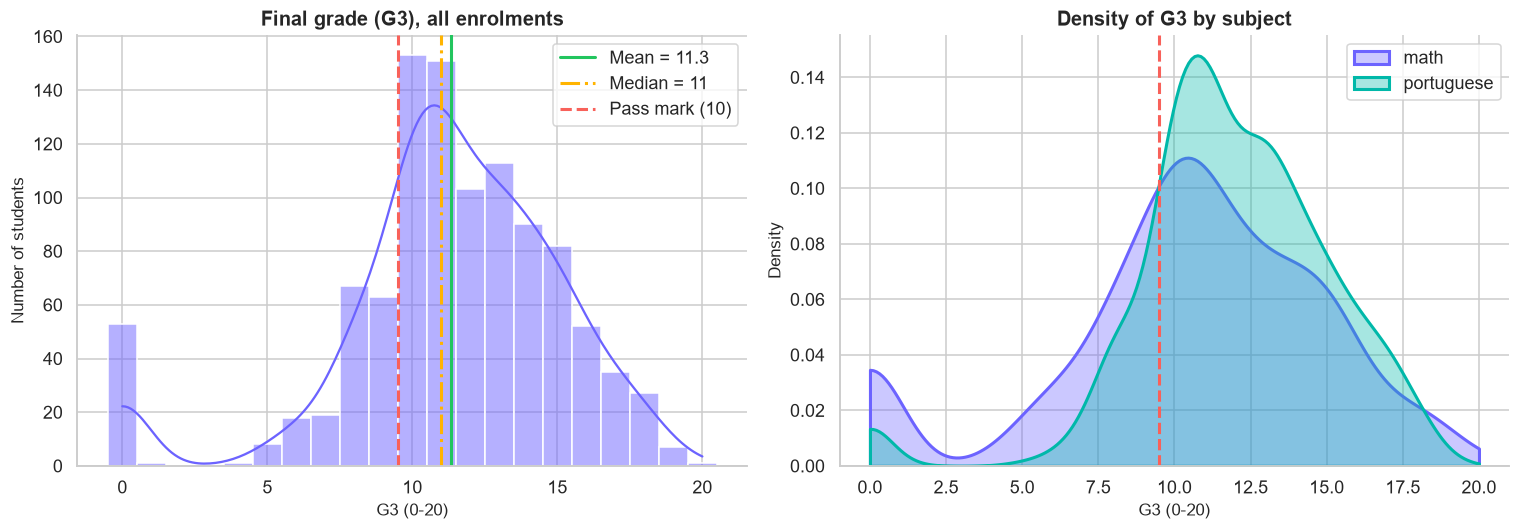

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bins = np.arange(-0.5, 21.5, 1)                             # one bin per integer grade

# Left: overall distribution with mean / median / pass mark
sns.histplot(df["G3"], bins=bins, kde=True, color=ACCENT[0], edgecolor="white", ax=axes[0])
axes[0].axvline(df["G3"].mean(),   color=GREEN,  lw=2, label=f"Mean = {df['G3'].mean():.1f}")
axes[0].axvline(df["G3"].median(), color=ACCENT[3], lw=2, ls="-.", label=f"Median = {df['G3'].median():.0f}")
axes[0].axvline(PASS_LINE, color=RED, lw=2, ls="--", label="Pass mark (10)")
axes[0].set(title="Final grade (G3), all enrolments", xlabel="G3 (0-20)", ylabel="Number of students")
axes[0].legend()

# Right: density by subject
for s in SUBJECT:
    sns.kdeplot(df.loc[df["subject"] == s, "G3"], fill=True, alpha=.35, lw=2, color=PAL[s],
                bw_adjust=.8, clip=(0, 20), label=s, ax=axes[1])
axes[1].axvline(PASS_LINE, color=RED, lw=2, ls="--")
axes[1].set(title="Density of G3 by subject", xlabel="G3 (0-20)", ylabel="Density")
axes[1].legend()

plt.tight_layout()
save_show(fig, "01_g3_distribution")

n_zero = int(df["zero_grade"].sum())
takeaway(f"Grades centre around <b>{df['G3'].median():.0f}/20</b> (mean {df['G3'].mean():.1f}). "
         f"There is a separate small spike at <b>0</b> ({n_zero} students, {n_zero/len(df):.1%}) that is not part of the main bell shape. "
         f"The overall pass rate is <b>{pass_rate(df['G3']):.0f}%</b>.")

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📊 Visual 2: Absences (a strongly skewed variable)</h3>
Absences are far from a bell shape. The histogram shows the long right tail and the box plot makes the outliers visible, which is why a capped copy (`absences_capped`) was created in Part 2.

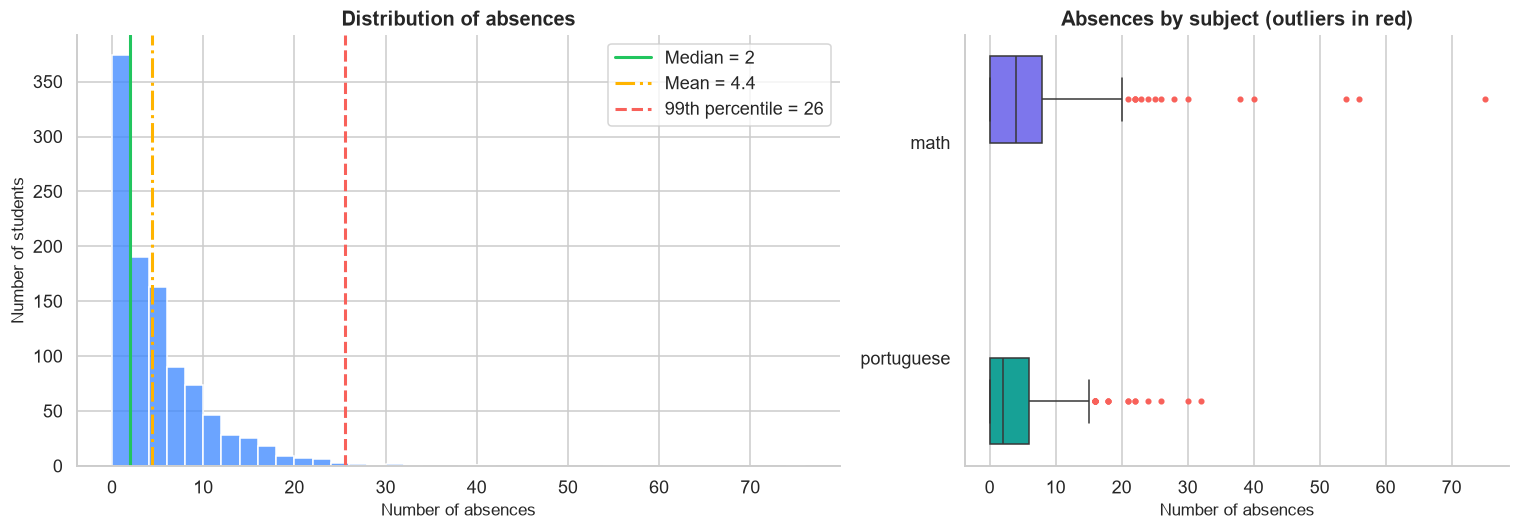

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.4, 1]})

sns.histplot(df["absences"], bins=range(0, int(df["absences"].max()) + 3, 2), color=ACCENT[4],
             edgecolor="white", ax=axes[0])
axes[0].axvline(df["absences"].median(), color=GREEN, lw=2, label=f"Median = {df['absences'].median():.0f}")
axes[0].axvline(df["absences"].mean(),   color=ACCENT[3], lw=2, ls="-.", label=f"Mean = {df['absences'].mean():.1f}")
axes[0].axvline(p99, color=RED, lw=2, ls="--", label=f"99th percentile = {p99:.0f}")
axes[0].set(title="Distribution of absences", xlabel="Number of absences", ylabel="Number of students")
axes[0].legend()

sns.boxplot(data=df, x="absences", y="subject", hue="subject", palette=PAL, legend=False,
            fliersize=3, flierprops={"markerfacecolor": RED, "markeredgecolor": RED}, ax=axes[1])
axes[1].set(title="Absences by subject (outliers in red)", xlabel="Number of absences", ylabel="")

plt.tight_layout()
save_show(fig, "02_absences_distribution")

takeaway(f"The typical student has only <b>{df['absences'].median():.0f}</b> absences (median), but the mean is pulled up to "
         f"<b>{df['absences'].mean():.1f}</b> by a few students with up to <b>{df['absences'].max()}</b>. "
         f"<b>{(df['absences'] == 0).mean():.0%}</b> of enrolments have no absences at all.")

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📊 Visual 3: Who are the students? (categorical profile)</h3>
Counts for the main categorical variables. This shows how balanced (or unbalanced) the groups are, which matters when we compare them later.

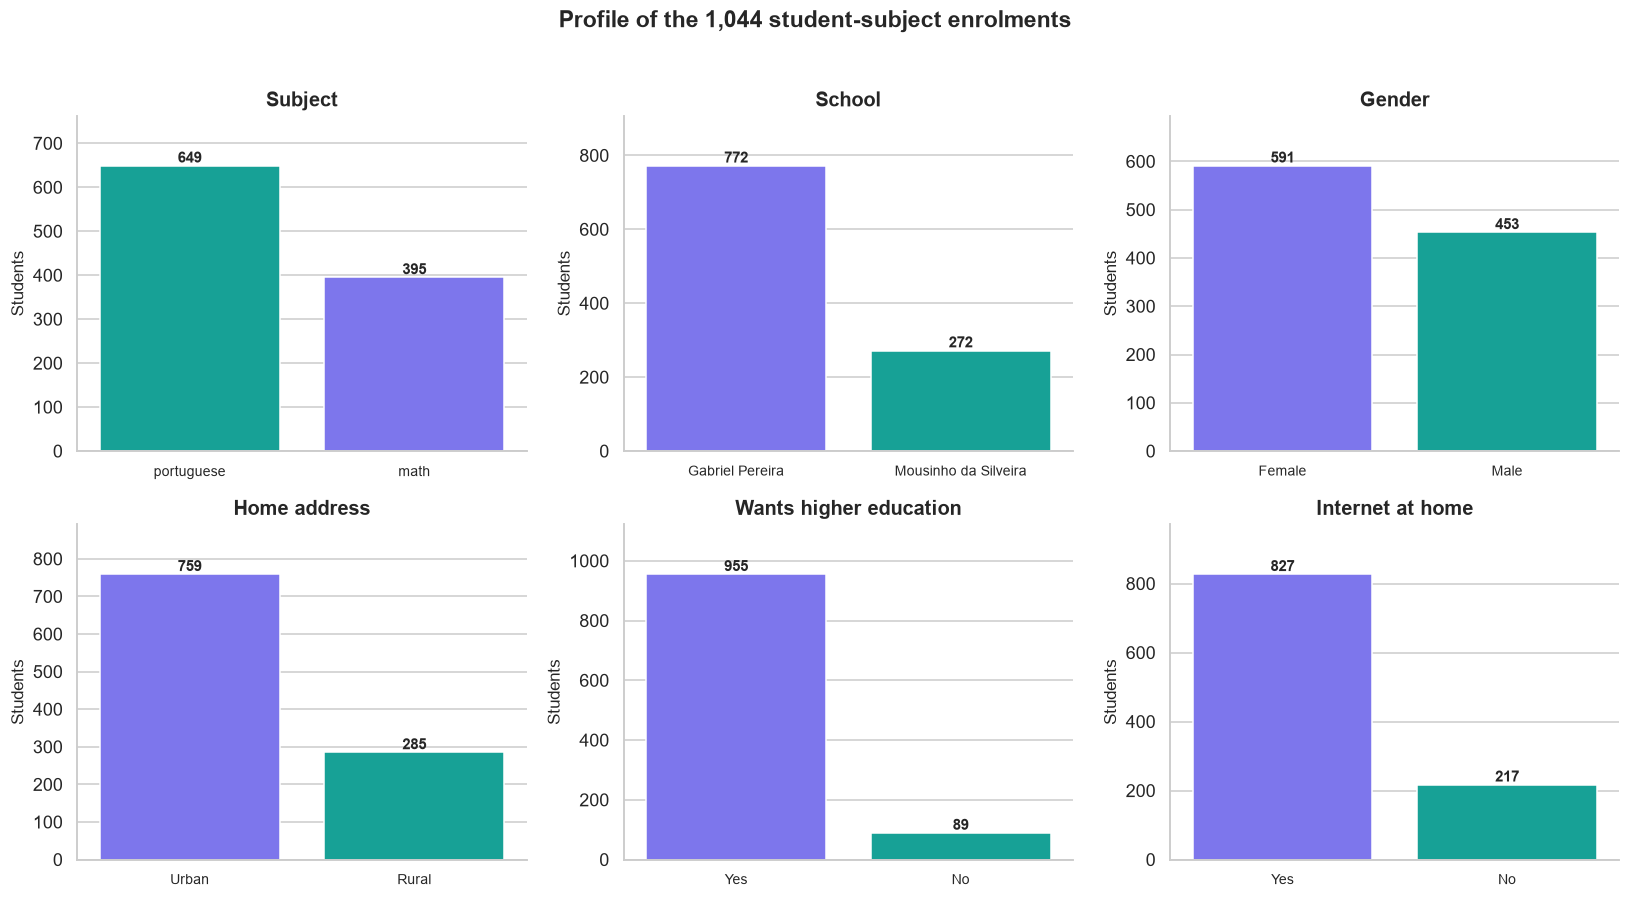

In [26]:
cat_cols = ["subject", "school", "gender", "address", "wants_higher_edu", "internet_access"]
nice = {"subject": "Subject", "school": "School", "gender": "Gender", "address": "Home address",
        "wants_higher_edu": "Wants higher education", "internet_access": "Internet at home"}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), cat_cols):
    order = df[c].astype(str).value_counts().index.tolist()
    colours = [PAL[o] for o in order] if c == "subject" else ACCENT[:len(order)]     # purple = Math, teal = Portuguese
    sns.countplot(data=df.assign(**{c: df[c].astype(str)}), x=c, order=order, hue=c, hue_order=order,
                  palette=colours, legend=False, edgecolor="white", ax=ax)
    annotate_bars(ax)
    ax.set(title=nice[c], xlabel="", ylabel="Students")
    ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
    ax.tick_params(axis="x", labelsize=9)
plt.suptitle("Profile of the 1,044 student-subject enrolments", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
save_show(fig, "03_categorical_profile")

takeaway(f"The groups are <b>unbalanced</b>: {df['school'].value_counts(normalize=True).iloc[0]:.0%} of rows come from "
         f"{df['school'].value_counts().index[0]}, {df['wants_higher_edu'].value_counts(normalize=True).iloc[0]:.0%} want higher education. "
         f"Small groups (for example the {int((df['wants_higher_edu']=='No').sum())} students who do not want higher education) "
         f"give less stable averages, so differences should be read with care.")

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📊 Visual 4: Ordinal scales (study time, failures, parents' education, lifestyle)</h3>
These variables are stored as numbers but are really *ordered categories* (1 = low … 5 = high), so bar charts describe them better than histograms.

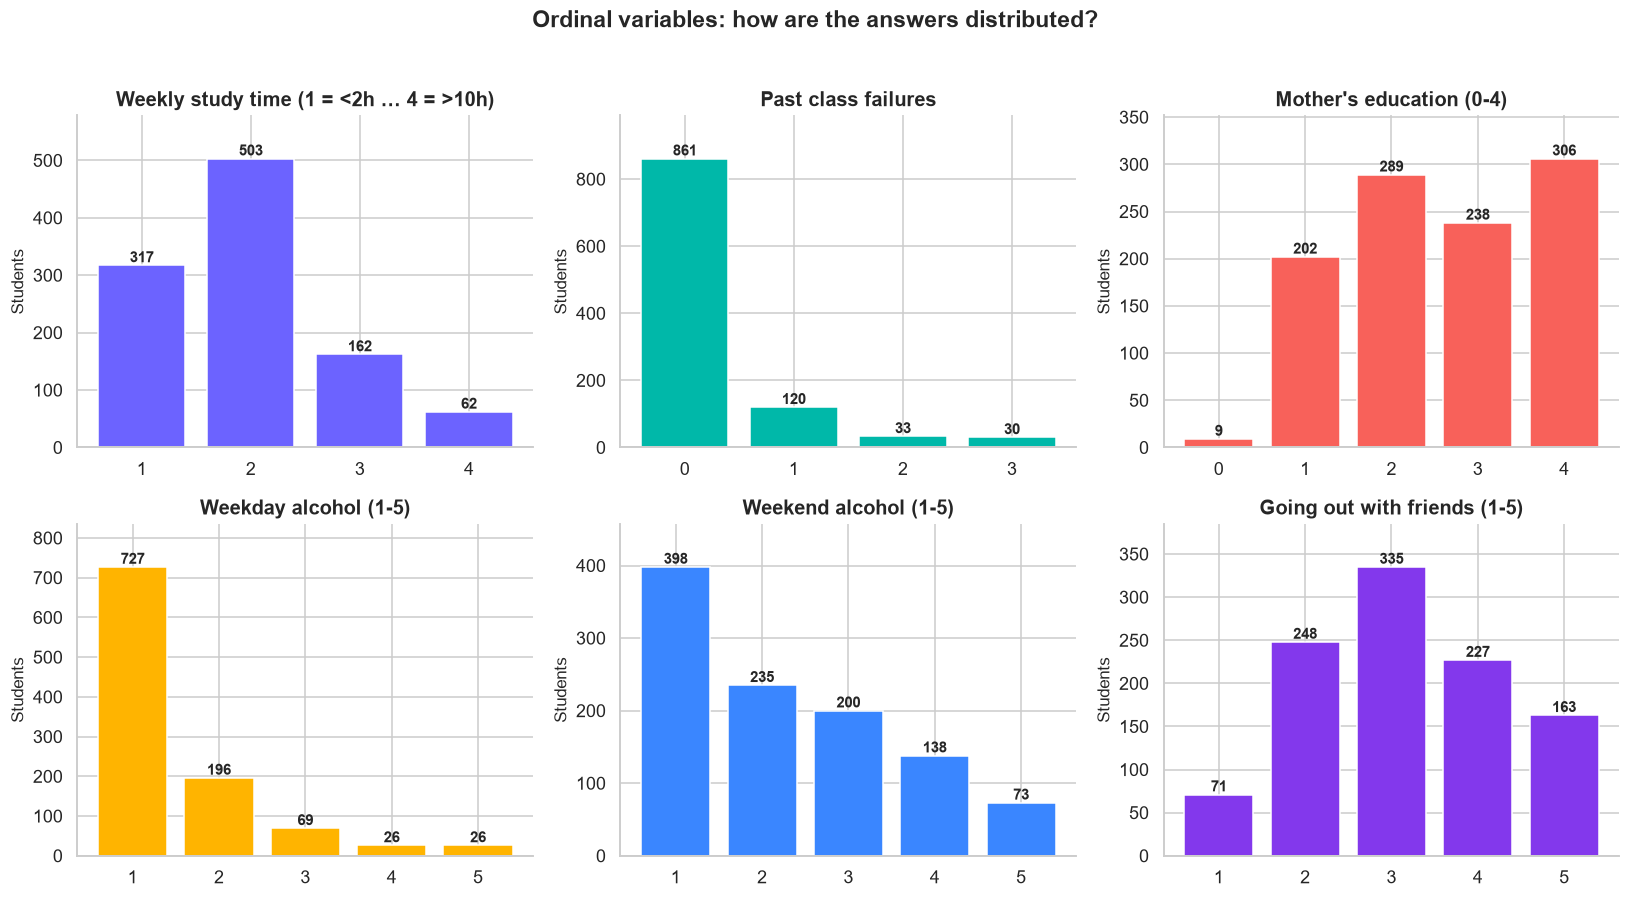

In [27]:
ord_cols = {"study_time": "Weekly study time (1 = <2h … 4 = >10h)", "failures": "Past class failures",
            "mother_edu": "Mother's education (0-4)", "weekday_alcohol": "Weekday alcohol (1-5)",
            "weekend_alcohol": "Weekend alcohol (1-5)", "go_out": "Going out with friends (1-5)"}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (c, label) in zip(axes.ravel(), ord_cols.items()):
    counts = df[c].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color=ACCENT[list(ord_cols).index(c) % len(ACCENT)], edgecolor="white")
    annotate_bars(ax)
    ax.set(title=label, xlabel="", ylabel="Students")
    ax.set_ylim(0, counts.max() * 1.15)
plt.suptitle("Ordinal variables: how are the answers distributed?", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
save_show(fig, "04_ordinal_variables")

takeaway(f"Most students are <b>low consumers of alcohol on weekdays</b> ({(df['weekday_alcohol']==1).mean():.0%} answered 1), "
         f"most have <b>no past failures</b> ({(df['failures']==0).mean():.0%}), and the most common study time is level "
         f"<b>{df['study_time'].mode()[0]}</b>. Failures are rare, so the 'failed before' groups are small.")

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📊 Visual 5: Performance bands and pass / fail</h3>
The final grade grouped into the bands defined in Part 2, and the share of students who pass in each subject.

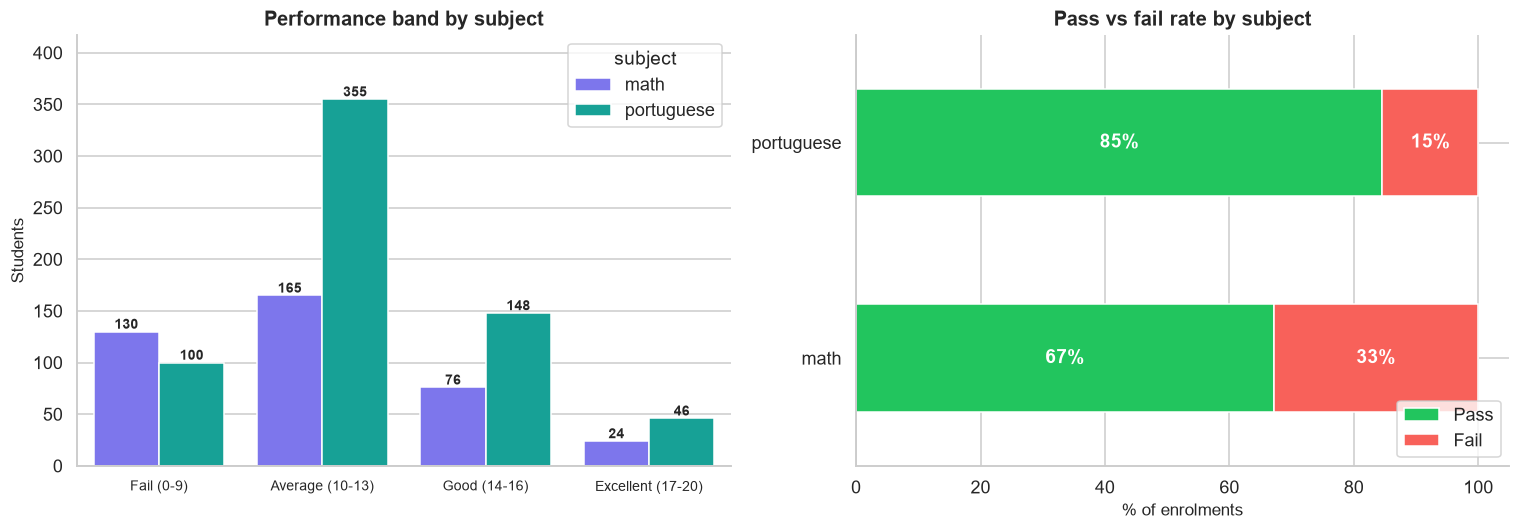

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

band_order = list(df["performance_band"].cat.categories)
sns.countplot(data=df, x="performance_band", order=band_order, hue="subject", hue_order=SUBJECT,
              palette=PAL, edgecolor="white", ax=axes[0])
annotate_bars(axes[0], fontsize=9)
axes[0].set(title="Performance band by subject", xlabel="", ylabel="Students")
axes[0].set_ylim(0, axes[0].get_ylim()[1] * 1.12)
axes[0].tick_params(axis="x", labelsize=9)

pf = (pd.crosstab(df["subject"], df["pass_fail"], normalize="index") * 100)[["Pass", "Fail"]]
pf.plot(kind="barh", stacked=True, color=[GREEN, RED], edgecolor="white", ax=axes[1])
for i, (_, row) in enumerate(pf.iterrows()):
    axes[1].text(row["Pass"] / 2, i, f"{row['Pass']:.0f}%", ha="center", va="center", color="white", fontweight="bold")
    axes[1].text(row["Pass"] + row["Fail"] / 2, i, f"{row['Fail']:.0f}%", ha="center", va="center", color="white", fontweight="bold")
axes[1].set(title="Pass vs fail rate by subject", xlabel="% of enrolments", ylabel="")
axes[1].legend(title="", loc="lower right")

plt.tight_layout()
save_show(fig, "05_performance_bands")

pr = df.groupby("subject", observed=True)["G3"].apply(pass_rate)
takeaway(f"<b>{pr.idxmax()}</b> has the higher pass rate (<b>{pr.max():.0f}%</b>) against <b>{pr.min():.0f}%</b> for {pr.idxmin()}. "
         f"The most common band is " + " and ".join(f"<b>{b}</b> in {s}" for s, b in df.groupby("subject", observed=True)["performance_band"].agg(lambda x: x.value_counts().idxmax()).items()) + ".")

### ✅ Summary of the univariate analysis
* The final grade is roughly bell-shaped around the middle of the scale, **plus an isolated group at 0**.
* `absences` is heavily right-skewed; a few extreme values pull the mean away from the median.
* The categorical groups are unbalanced, so group comparisons need to be read together with group sizes.
* Math has a clearly lower pass rate than Portuguese.

<h2 style="color:#E06A00;border-bottom:3px solid #E06A00;padding-bottom:6px;margin-top:30px;">4.2 Bivariate Analysis</h2>
Bivariate analysis looks at the **relationship between the final grade and one other variable** at a time.

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📊 Visual 6: Final grade by past failures</h3>
Box plots show the median, the spread and the outliers of `G3` for each number of previous class failures. Individual students are drawn as dots.

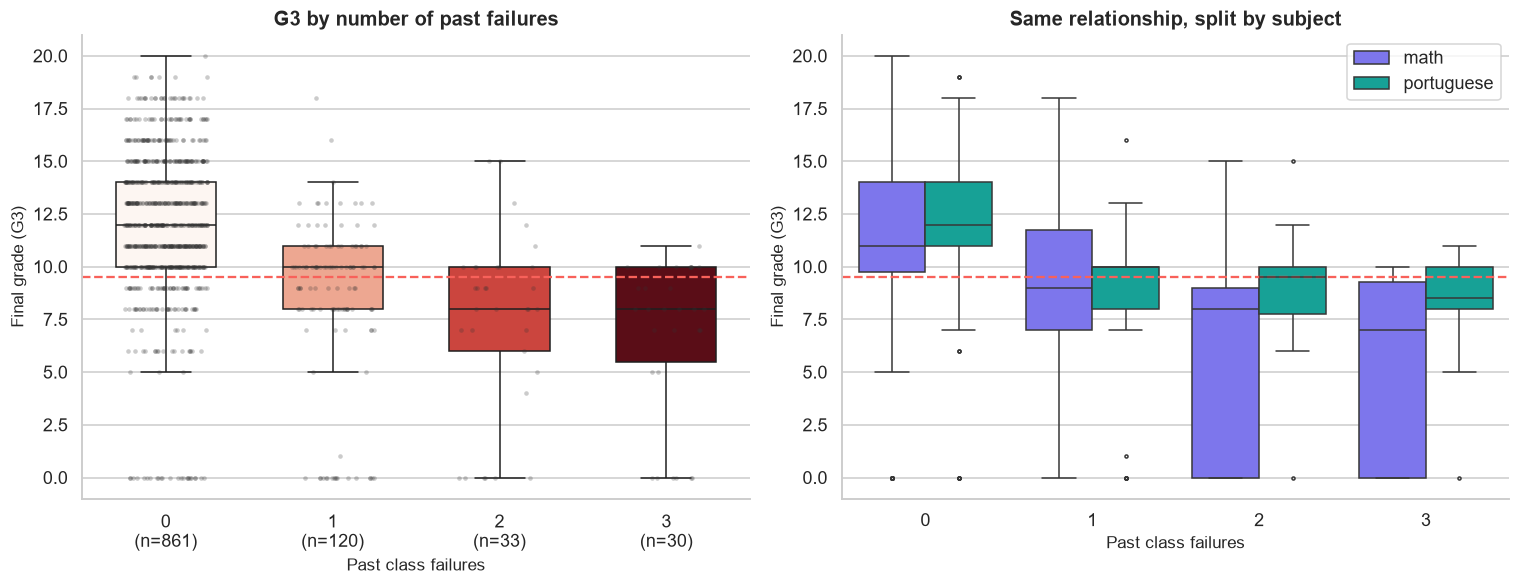

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

counts = df["failures"].value_counts().sort_index()
labels = [f"{k}\n(n={v})" for k, v in counts.items()]

sns.boxplot(data=df, x="failures", y="G3", hue="failures", palette="Reds", legend=False,
            fliersize=0, width=.6, ax=axes[0])
sns.stripplot(data=df, x="failures", y="G3", color="#333", alpha=.25, size=3, jitter=.25, ax=axes[0])
axes[0].axhline(PASS_LINE, color=RED, ls="--", lw=1.5)
axes[0].set_xticks(range(len(counts)), labels)
axes[0].set(title="G3 by number of past failures", xlabel="Past class failures", ylabel="Final grade (G3)")

sns.boxplot(data=df, x="failures", y="G3", hue="subject", hue_order=SUBJECT, palette=PAL,
            fliersize=2, ax=axes[1])
axes[1].axhline(PASS_LINE, color=RED, ls="--", lw=1.5)
axes[1].set(title="Same relationship, split by subject", xlabel="Past class failures", ylabel="Final grade (G3)")
axes[1].legend(title="")

plt.tight_layout()
save_show(fig, "06_failures_boxplot")

g = df.groupby("failures")["G3"].mean()
takeaway(f"Mean G3 goes from <b>{g.iloc[0]:.1f}</b> (no failures) to <b>{g.iloc[-1]:.1f}</b> ({g.index[-1]} failures). "
         f"Look at how the boxes move as failures rise, in <b>both</b> subjects: past failure is one of the clearest warning signs.")

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📊 Visual 7: Study time and final grade</h3>
Left: average final grade with a 95% confidence interval for each study-time level, by subject. Right: the pass rate for each level.

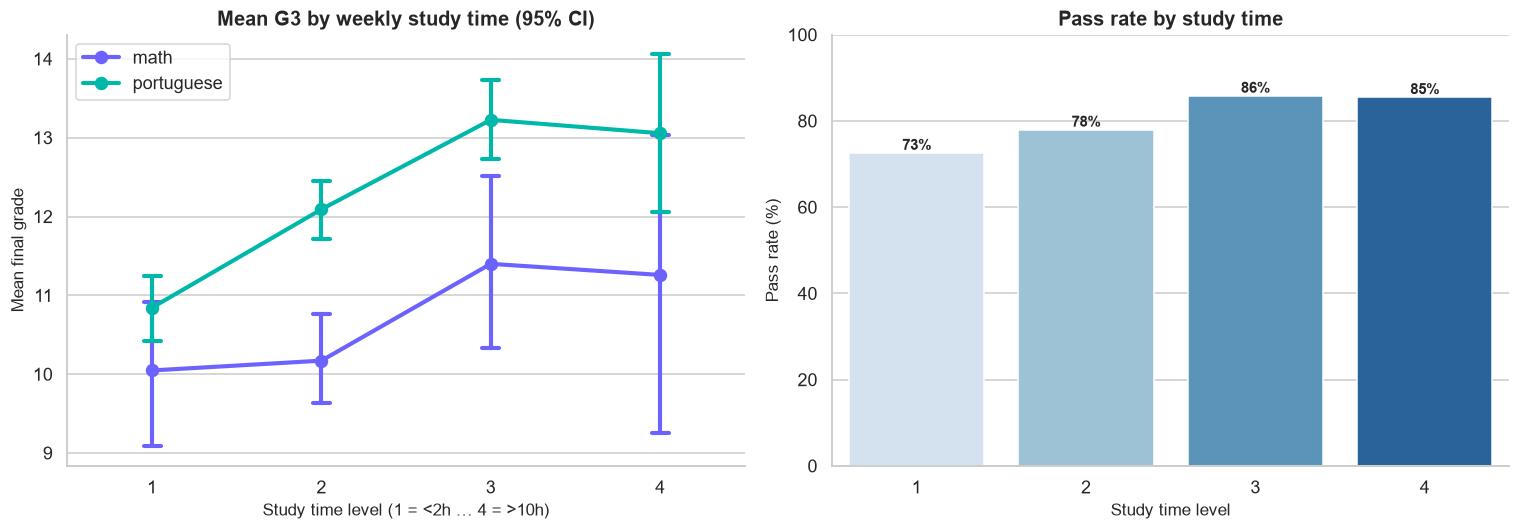

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.pointplot(data=df, x="study_time", y="G3", hue="subject", hue_order=SUBJECT, palette=PAL,
              errorbar=("ci", 95), capsize=.1, markers="o", ax=axes[0])
axes[0].set(title="Mean G3 by weekly study time (95% CI)", xlabel="Study time level (1 = <2h … 4 = >10h)", ylabel="Mean final grade")
axes[0].legend(title="")

pr_study = df.groupby("study_time")["G3"].apply(pass_rate)
sns.barplot(x=pr_study.index.astype(str), y=pr_study.values, hue=pr_study.index.astype(str), palette="Blues", legend=False,
            edgecolor="white", ax=axes[1])
annotate_bars(axes[1], fmt="{:.0f}%")
axes[1].set(title="Pass rate by study time", xlabel="Study time level", ylabel="Pass rate (%)", ylim=(0, 100))

plt.tight_layout()
save_show(fig, "07_study_time")

m = df.groupby("study_time")["G3"].mean()
takeaway(f"Students at the lowest study level average <b>{m.loc[1]:.1f}</b>, against <b>{m.loc[m.idxmax()]:.1f}</b> at the best level (level {m.idxmax()}). "
         f"The step from level 1 to level 2 is <b>{m.loc[2]-m.loc[1]:+.1f}</b> points, while the step from level 2 to level {m.index.max()} is <b>{m.iloc[-1]-m.loc[2]:+.1f}</b>. "
         f"Check the confidence intervals: where they overlap, extra hours are not clearly better.")

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📊 Visual 8: Earlier grades predict the final grade</h3>
Scatter plots of `G1` and `G2` against `G3`. Students with `G3 = 0` are marked with red crosses and are left out of the dashed regression line, because they behave differently (see Part 3).

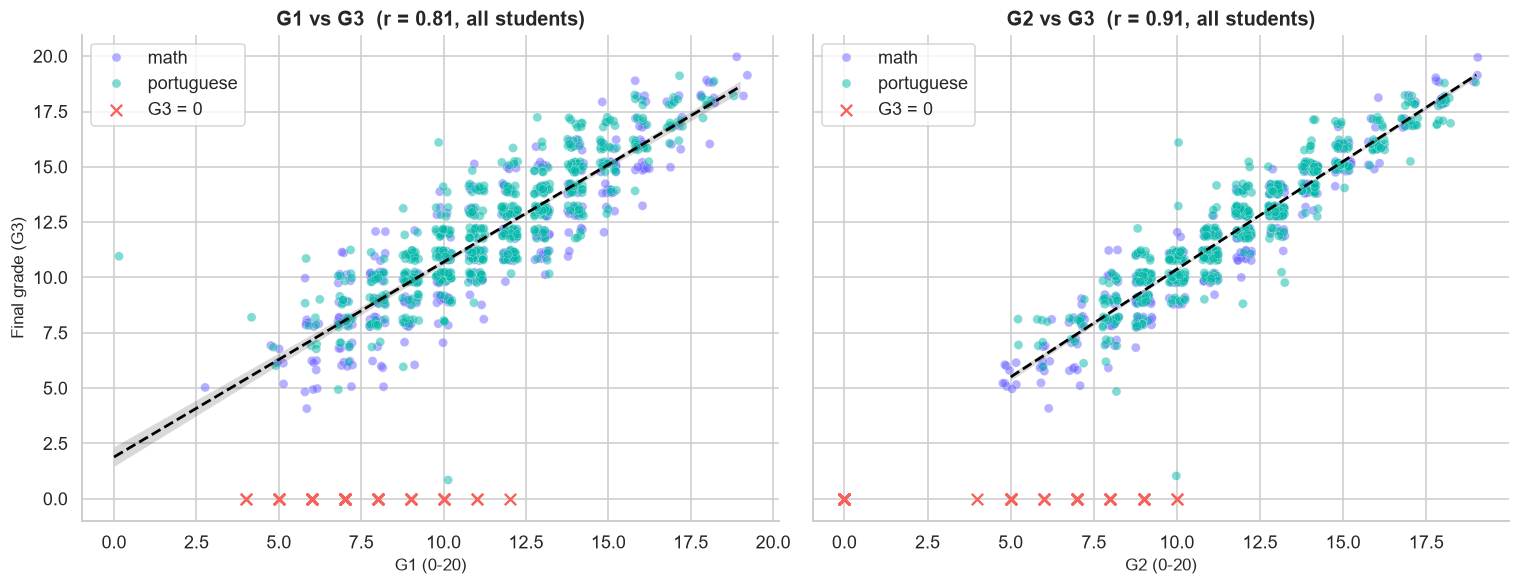

In [31]:
rng = np.random.default_rng(42)                              # small random jitter so overlapping integer grades stay visible
jit = lambda s: s + rng.uniform(-.25, .25, len(s))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, x in zip(axes, ["G1", "G2"]):
    sns.scatterplot(x=jit(df_graded[x]), y=jit(df_graded["G3"]), hue=df_graded["subject"].astype(str),
                    hue_order=SUBJECT, palette=PAL, alpha=.5, s=35, edgecolor="white", linewidth=.3, ax=ax)
    ax.scatter(zeros[x], zeros["G3"], marker="x", color=RED, s=55, label="G3 = 0")
    sns.regplot(data=df_graded, x=x, y="G3", scatter=False, color="black",
                line_kws={"lw": 1.8, "ls": "--"}, ax=ax)
    r = df[x].corr(df["G3"])
    ax.set(title=f"{x} vs G3  (r = {r:.2f}, all students)", xlabel=f"{x} (0-20)", ylabel="Final grade (G3)")
    ax.legend(title="", loc="upper left")
plt.tight_layout()
save_show(fig, "08_previous_grades_scatter")

takeaway(f"Previous grades are by far the strongest predictor: <b>r = {df['G1'].corr(df['G3']):.2f}</b> for G1 and "
         f"<b>r = {df['G2'].corr(df['G3']):.2f}</b> for G2. The points hug the diagonal, so a student's level is "
         f"<b>already visible in the first period</b>. The red crosses are students who had low grades and then received 0.")

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📊 Visual 9: Gender, address and ambition (split by subject)</h3>
Mean final grade for three background factors, with 95% confidence intervals as error bars. Splitting by subject matters because the effect is not always the same in both.

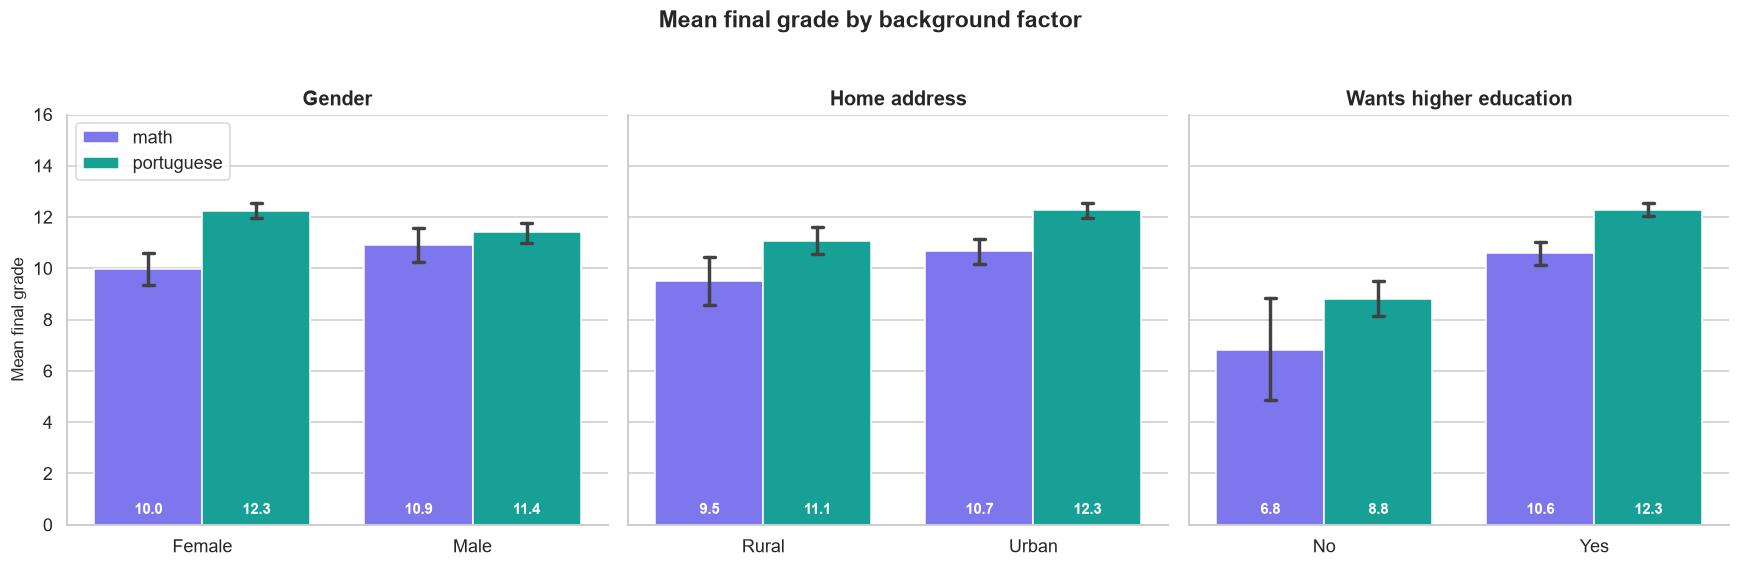

In [32]:
factors = {"gender": "Gender", "address": "Home address", "wants_higher_edu": "Wants higher education"}
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, (c, label) in zip(axes, factors.items()):
    sns.barplot(data=df, x=c, y="G3", hue="subject", hue_order=SUBJECT, palette=PAL,
                errorbar=("ci", 95), capsize=.08, edgecolor="white", ax=ax)
    ax.set(title=label, xlabel="", ylabel="Mean final grade" if c == "gender" else "")
    ax.set_ylim(0, 16)
    for p in ax.patches:                                     # value labels inside the bars
        if p.get_height() > 0:
            ax.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2, 0.3),
                        ha="center", va="bottom", color="white", fontweight="bold", fontsize=10)
    if c != "gender":
        ax.get_legend().remove()
axes[0].legend(title="", loc="upper left")
plt.suptitle("Mean final grade by background factor", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
save_show(fig, "09_background_factors")

pg = df.pivot_table(index="subject", columns="gender", values="G3", aggfunc="mean", observed=True)
he = df.groupby("wants_higher_edu", observed=True)["G3"].mean()
gap_g = {s: pg.loc[s, "Female"] - pg.loc[s, "Male"] for s in SUBJECT}          # female minus male, per subject
opposite = len({np.sign(v) for v in gap_g.values()}) > 1
ad = df.groupby("address", observed=True)["G3"].mean()
takeaway(f"Students who want higher education average <b>{he['Yes']:.1f}</b> vs <b>{he['No']:.1f}</b> for those who do not "
         f"(a gap of <b>{he['Yes']-he['No']:+.1f}</b>). Female minus male mean G3: " +
         ", ".join(f"<b>{s}</b> {v:+.2f}" for s, v in gap_g.items()) +
         (". The gender gap goes in <b>opposite directions</b> in the two subjects. " if opposite else ". The gender gap has the same direction in both subjects. ") +
         f"Urban minus rural: <b>{ad.get('Urban', np.nan) - ad.get('Rural', np.nan):+.1f}</b>.")

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📊 Visual 10: School and school-support factors</h3>
Do the school, internet access, family support and paid extra classes matter? Differences between the two bars of each pair are what to look at.

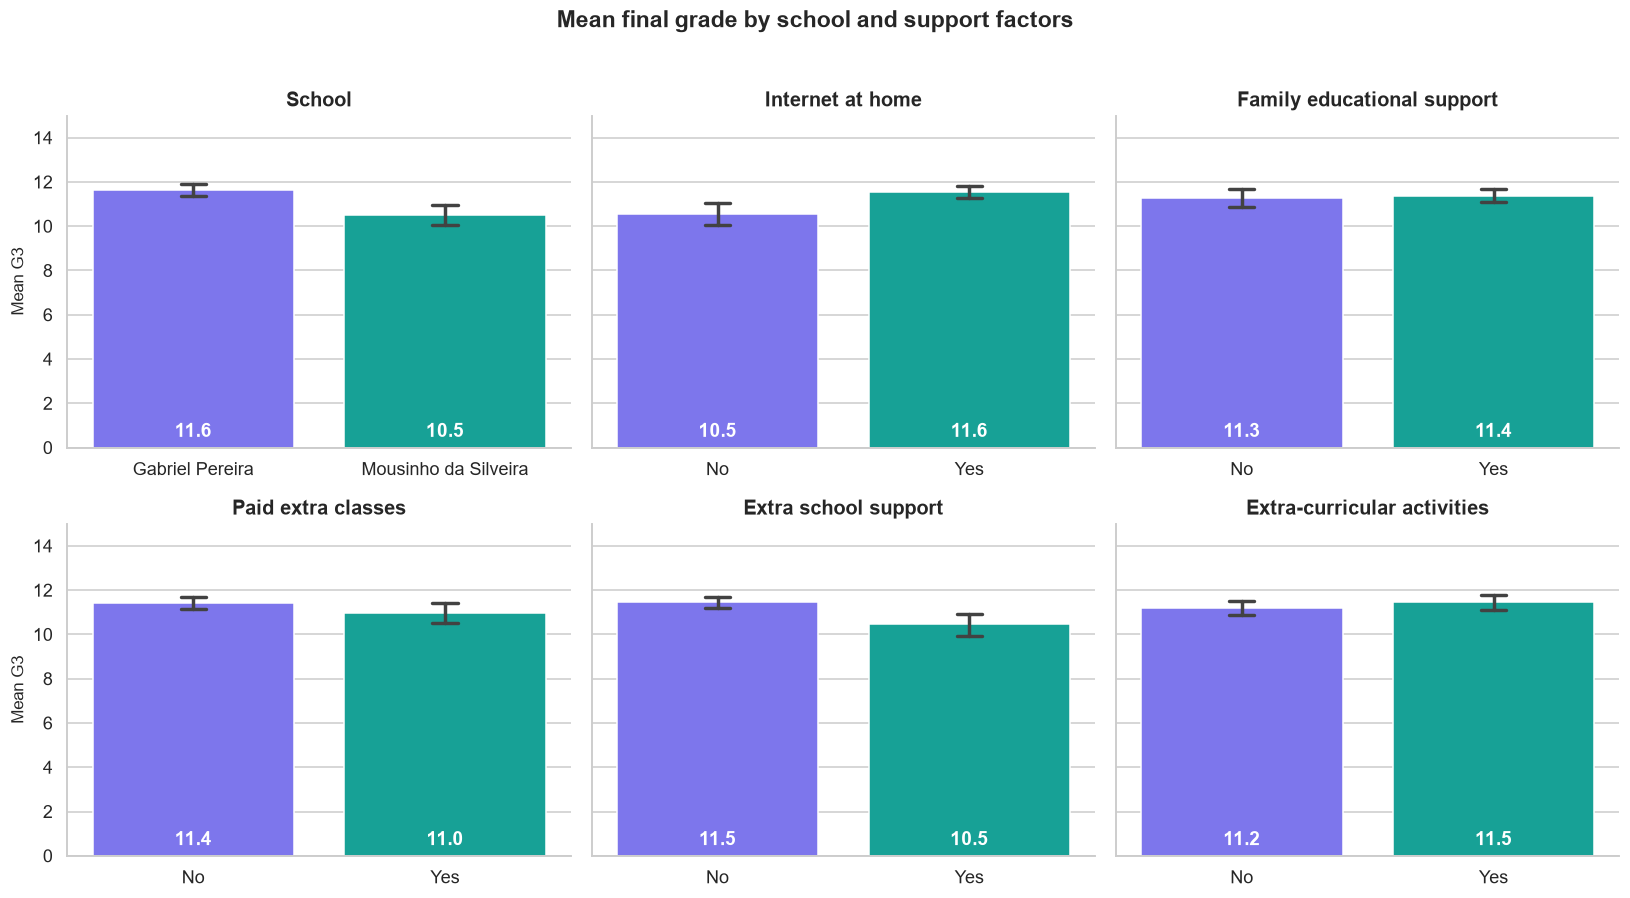

In [33]:
factors2 = {"school": "School", "internet_access": "Internet at home", "family_support": "Family educational support",
            "paid_classes": "Paid extra classes", "school_support": "Extra school support", "extracurricular": "Extra-curricular activities"}
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for ax, (c, label) in zip(axes.ravel(), factors2.items()):
    order = sorted(df[c].astype(str).unique())
    sns.barplot(data=df.assign(**{c: df[c].astype(str)}), x=c, y="G3", order=order, hue=c, hue_order=order,
                palette=ACCENT[:len(order)], errorbar=("ci", 95), capsize=.1, edgecolor="white", legend=False, ax=ax)
    for p in ax.patches:
        if p.get_height() > 0:
            ax.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2, 0.3), ha="center", va="bottom",
                        color="white", fontweight="bold")
    ax.set(title=label, xlabel="", ylabel="Mean G3")
    ax.set_ylim(0, 15)
plt.suptitle("Mean final grade by school and support factors", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
save_show(fig, "10_school_support_factors")

sup = df.groupby("school_support", observed=True)["G3"].mean()
biggest = max(factors2, key=lambda c: abs(df.groupby(c, observed=True)["G3"].mean().diff().dropna().iloc[0]))
bg = df.groupby(biggest, observed=True)["G3"].mean()
direction = "lower" if sup["Yes"] < sup["No"] else "higher"
takeaway(f"The largest gap among these factors is <b>{factors2[biggest]}</b> ({bg.index[0]}: {bg.iloc[0]:.1f} vs {bg.index[1]}: {bg.iloc[1]:.1f}). "
         f"Extra school support is associated with a <b>{direction}</b> mean ({sup['Yes']:.1f} with vs {sup['No']:.1f} without). "
         + (f"A lower mean would not mean support harms: schools usually give support to students who are <b>already struggling</b> (correlation ≠ causation)."
          if direction == "lower" else f"Remember that this is an association, not proof that support causes the difference (correlation ≠ causation)."))

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📊 Visual 11: Absences, and the zero-grade effect</h3>
Part 3 found that all students with `G3 = 0` have **zero absences**, which hides the real effect of absences. Left: mean grade by absence group with and without those students. Right: how the zero grades are concentrated in the 'None' group.

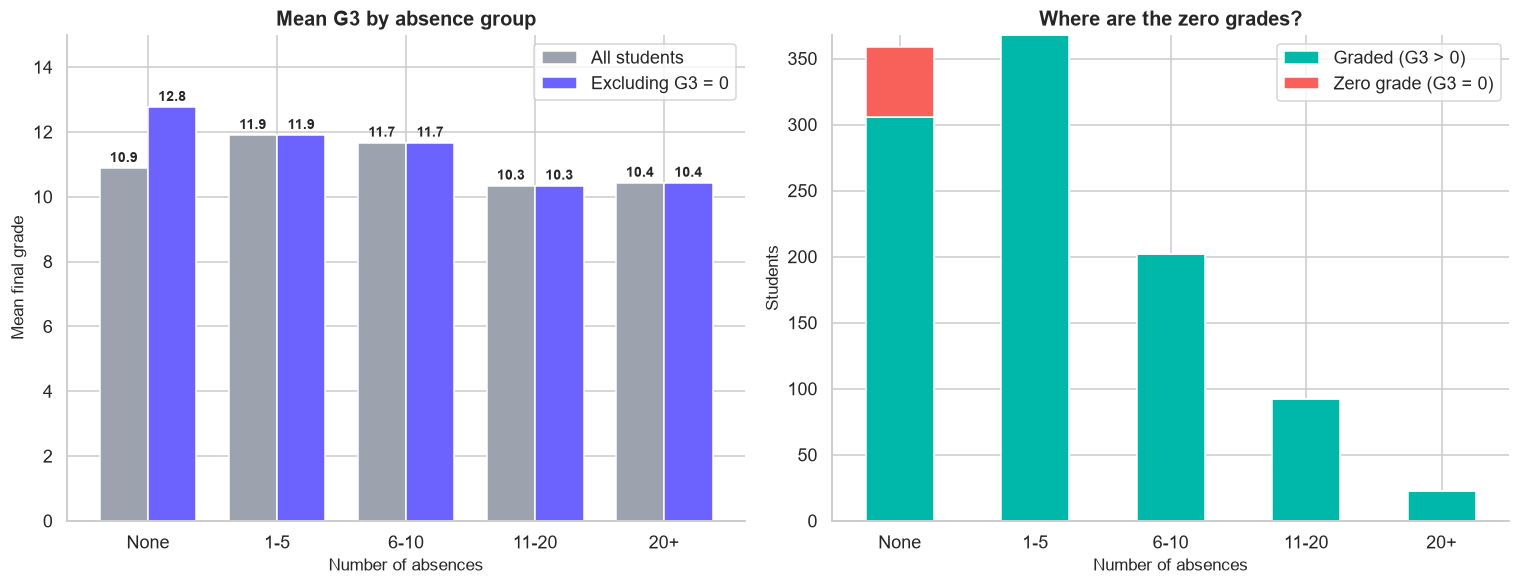

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

cmp = pd.DataFrame({"All students": df.groupby("absence_group", observed=True)["G3"].mean(),
                    "Excluding G3 = 0": df_graded.groupby("absence_group", observed=True)["G3"].mean()})
cmp.plot(kind="bar", color=[GREY, ACCENT[0]], edgecolor="white", width=.75, ax=axes[0])
for cont in axes[0].containers:
    axes[0].bar_label(cont, fmt="%.1f", fontsize=9, fontweight="bold", padding=2)
axes[0].set(title="Mean G3 by absence group", xlabel="Number of absences", ylabel="Mean final grade", ylim=(0, 15))
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="")

zc = pd.crosstab(df["absence_group"], df["zero_grade"]).rename(columns={False: "Graded (G3 > 0)", True: "Zero grade (G3 = 0)"})
zc.plot(kind="bar", stacked=True, color=[ACCENT[1], RED], edgecolor="white", ax=axes[1])
axes[1].set(title="Where are the zero grades?", xlabel="Number of absences", ylabel="Students")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="")

plt.tight_layout()
save_show(fig, "11_absences_zero_effect")

c_all, c_gr = df["absences"].corr(df["G3"]), df_graded["absences"].corr(df_graded["G3"])
takeaway(f"All <b>{int(zc['Zero grade (G3 = 0)'].sum())}</b> zero grades sit in the <b>'None'</b> absence group, which makes the 'no absences' students look weaker than they really are. "
         f"Correlation of absences with G3 is only <b>{c_all:.2f}</b> for everyone but <b>{c_gr:.2f}</b> once zero grades are excluded: "
         f"the absence effect is <b>real but was masked</b>.")

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📊 Visual 12: Alcohol consumption and final grade</h3>
Mean final grade at each level of weekday and weekend alcohol consumption (1 = very low, 5 = very high), with 95% confidence intervals.

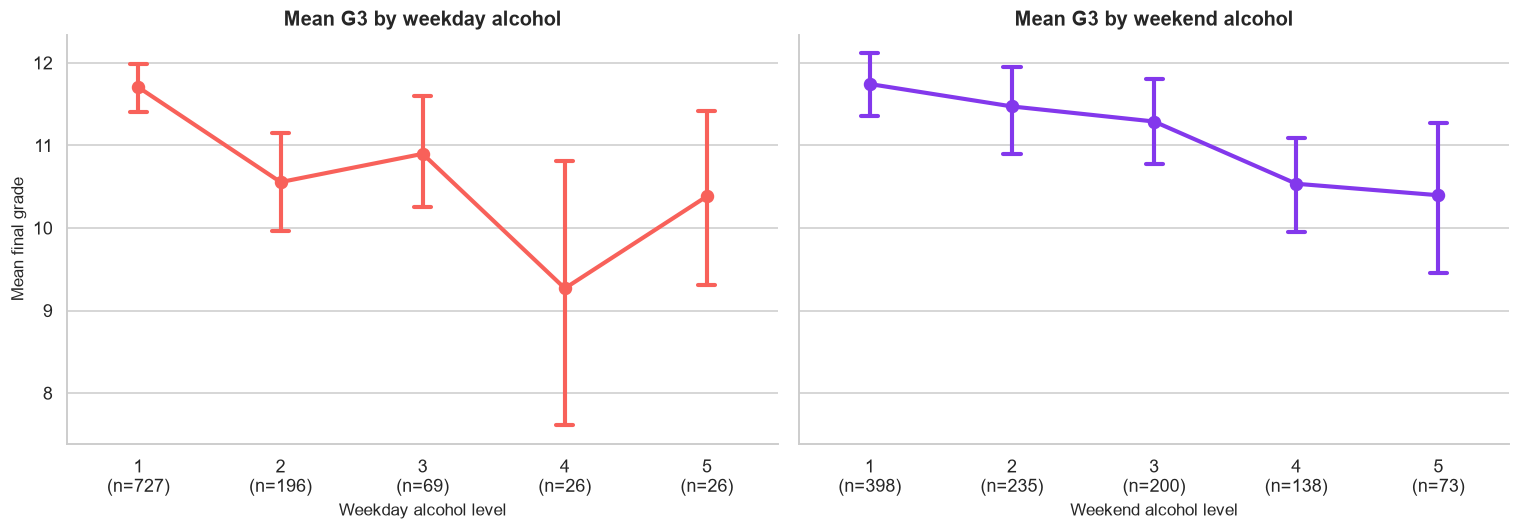

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (c, label, colr) in zip(axes, [("weekday_alcohol", "Weekday alcohol", ACCENT[2]), ("weekend_alcohol", "Weekend alcohol", ACCENT[5])]):
    sns.pointplot(data=df, x=c, y="G3", color=colr, errorbar=("ci", 95), capsize=.12, ax=ax)
    n = df[c].value_counts().sort_index()
    ax.set_xticks(range(len(n)), [f"{k}\n(n={v})" for k, v in n.items()])
    ax.set(title=f"Mean G3 by {label.lower()}", xlabel=f"{label} level", ylabel="Mean final grade" if c == "weekday_alcohol" else "")
plt.tight_layout()
save_show(fig, "12_alcohol")

wd = df.groupby("weekday_alcohol")["G3"].mean()
ra = df["weekday_alcohol"].corr(df["G3"])
move = "down" if wd.iloc[-1] < wd.iloc[0] else "up"
takeaway(f"Mean G3 moves {move} from <b>{wd.iloc[0]:.1f}</b> at the lowest weekday level to <b>{wd.iloc[-1]:.1f}</b> at the highest. "
         f"The correlation is {'weak' if abs(ra) < .3 else 'moderate'} (<b>r = {ra:.2f}</b>) and the highest levels have few students "
         f"(see the n values), so any trend should be read as a <b>mild signal rather than a strong driver</b>.")

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📊 Visual 13: How grades move during the year (G1 → G2 → G3)</h3>
Left: average grade at each period by subject. Right: the share of students whose grade declined, stayed stable or improved between `G1` and `G3`.

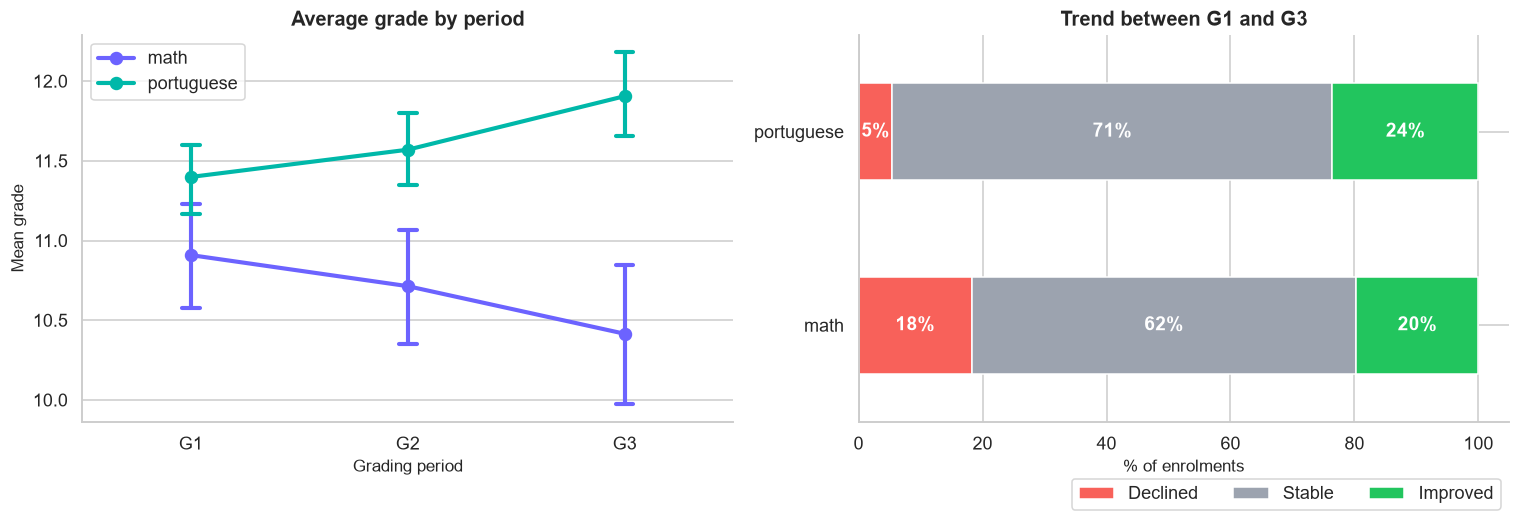

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

prog = df.melt(id_vars="subject", value_vars=["G1", "G2", "G3"], var_name="period", value_name="grade")
sns.pointplot(data=prog, x="period", y="grade", hue="subject", hue_order=SUBJECT, palette=PAL,
              errorbar=("ci", 95), capsize=.08, markers="o", ax=axes[0])
axes[0].set(title="Average grade by period", xlabel="Grading period", ylabel="Mean grade")
axes[0].legend(title="")

tr = pd.crosstab(df["subject"], df["trend"], normalize="index") * 100
tr = tr[["Declined", "Stable", "Improved"]]
tr.plot(kind="barh", stacked=True, color=[RED, GREY, GREEN], edgecolor="white", ax=axes[1])
for i, (_, row) in enumerate(tr.iterrows()):
    left = 0
    for v in row:
        axes[1].text(left + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontweight="bold")
        left += v
axes[1].set(title="Trend between G1 and G3", xlabel="% of enrolments", ylabel="")
axes[1].legend(title="", loc="lower right", ncol=3, bbox_to_anchor=(1, -0.25))

plt.tight_layout()
save_show(fig, "13_grade_progression")

mm = df.groupby("subject", observed=True)[["G1", "G3"]].mean()
d = (mm["G3"] - mm["G1"])
takeaway(f"Average change from G1 to G3: " + ", ".join(f"<b>{s}</b> {v:+.2f}" for s, v in d.items()) +
         f". Overall <b>{(df['trend'] == 'Stable').mean():.0%}</b> of students are stable between G1 and G3 (declined: {(df['trend'] == 'Declined').mean():.0%}, improved: {(df['trend'] == 'Improved').mean():.0%}), "
         f"which supports using the first-period grade as an early-warning signal.")

### ✅ Summary of the bivariate analysis
* **Past failures** and **earlier grades** have the strongest links with the final grade.
* **Wanting higher education** is associated with a much higher grade; **study time** helps most when moving away from the lowest level.
* **Gender** differences go in opposite directions in the two subjects; urban/rural and school differences are small.
* **Absences** only show their real (negative) effect once the zero-grade students are separated out.
* Support variables look "negative" because support goes to students who already struggle (**correlation ≠ causation**).

<h2 style="color:#E06A00;border-bottom:3px solid #E06A00;padding-bottom:6px;margin-top:30px;">4.3 Multivariate Analysis</h2>
Multivariate analysis studies **several variables at the same time**: correlation matrices, interactions, and combined views.

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📊 Visual 14: Correlation heatmap</h3>
Correlation (r) between all numeric variables. Dark red = strong positive, dark blue = strong negative. Only the lower triangle is shown to avoid repeating values.

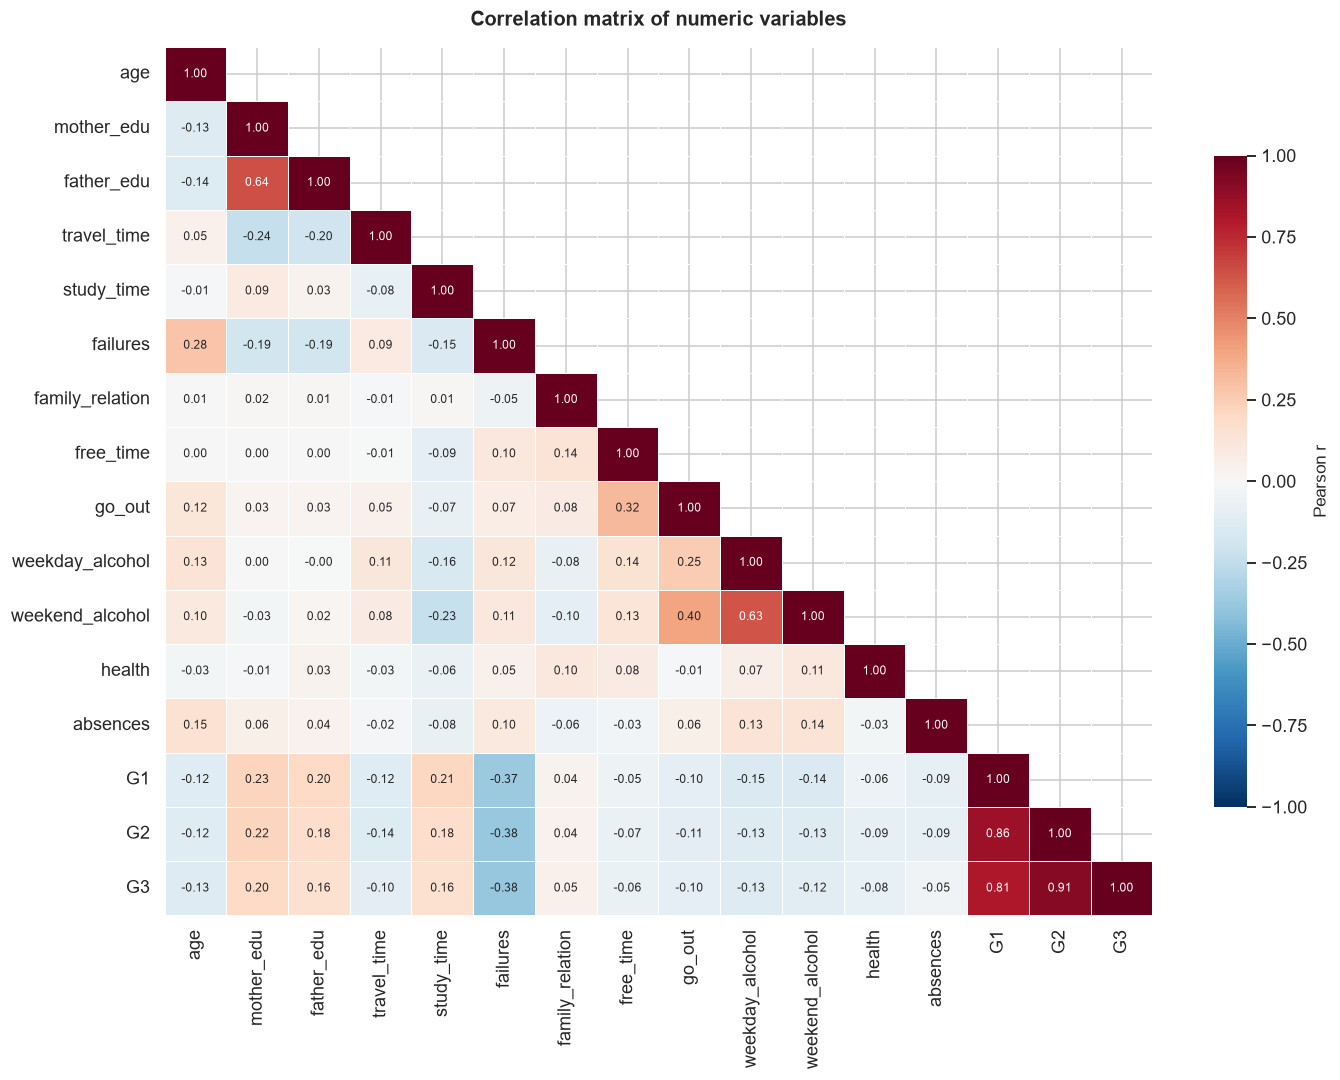

In [37]:
num_cols = ["age", "mother_edu", "father_edu", "travel_time", "study_time", "failures", "family_relation",
            "free_time", "go_out", "weekday_alcohol", "weekend_alcohol", "health", "absences", "G1", "G2", "G3"]
corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", annot_kws={"size": 8}, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=.5, linecolor="white", cbar_kws={"shrink": .75, "label": "Pearson r"}, ax=ax)
ax.set_title("Correlation matrix of numeric variables", pad=14)
plt.tight_layout()
save_show(fig, "14_correlation_heatmap")

pairs = (corr.where(~mask & ~np.eye(len(corr), dtype=bool)).stack().rename("r").reset_index())
pairs.columns = ["v1", "v2", "r"]
non_grade = pairs[~pairs["v1"].isin(["G1", "G2", "G3"]) & ~pairs["v2"].isin(["G1", "G2", "G3"])]
top = non_grade.reindex(non_grade["r"].abs().sort_values(ascending=False).index).iloc[0]
takeaway(f"The block of <b>G1, G2, G3</b> is almost perfectly correlated (r up to {corr.loc['G2','G3']:.2f}). Among the other variables the strongest pair is "
         f"<b>{top['v1']} ↔ {top['v2']}</b> (r = {top['r']:.2f}), so some predictors carry overlapping information. "
         f"Among non-grade variables, the largest |r| with G3 is <b>{corr['G3'].drop(['G1','G2','G3']).abs().max():.2f}</b>.")

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📊 Visual 15: What drives the final grade? (ranked correlations)</h3>
The same information focused on the target. Bars to the right push the grade up, bars to the left pull it down. `G1` and `G2` are shown in a lighter shade because they are earlier measurements of the same outcome, not independent "causes".

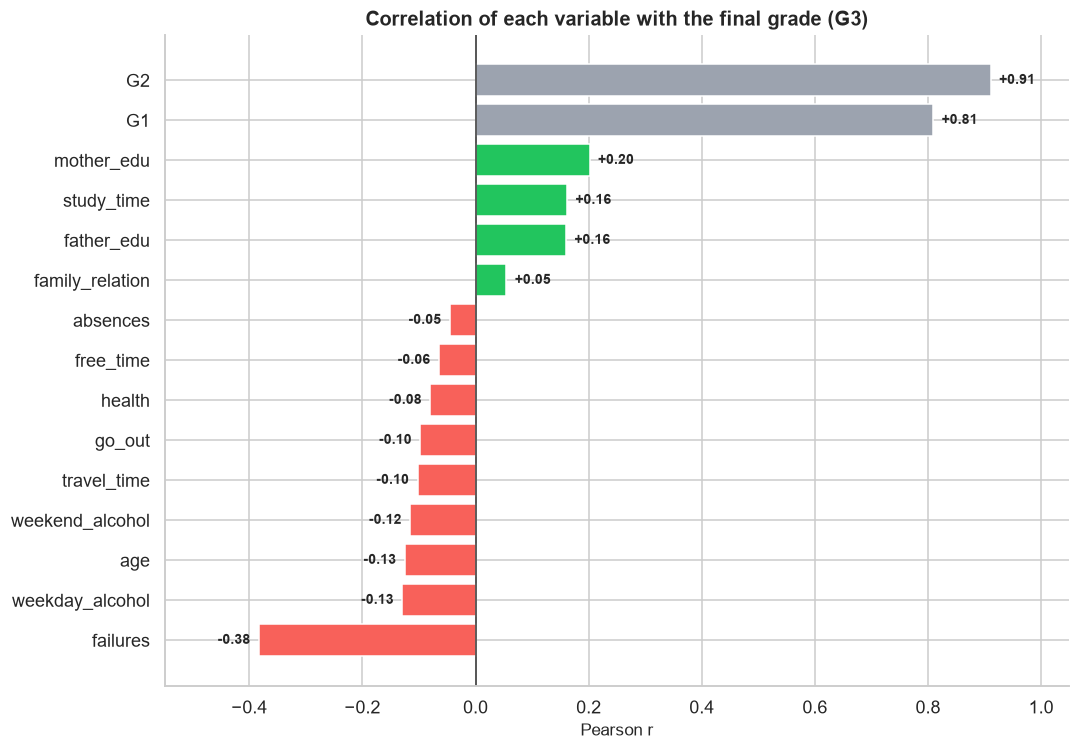

In [38]:
r_g3 = corr["G3"].drop("G3").sort_values()
colors = [GREY if v in ("G1", "G2") else (GREEN if r_g3[v] > 0 else RED) for v in r_g3.index]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(r_g3.index, r_g3.values, color=colors, edgecolor="white")
for y, v in enumerate(r_g3.values):
    ax.text(v + (0.015 if v >= 0 else -0.015), y, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=9, fontweight="bold")
ax.axvline(0, color="#333", lw=1)
ax.set(title="Correlation of each variable with the final grade (G3)", xlabel="Pearson r", xlim=(-.55, 1.05))
plt.tight_layout()
save_show(fig, "15_g3_correlation_ranking")

ex = r_g3.drop(["G1", "G2"])
takeaway(f"Excluding G1/G2, the strongest <b>negative</b> factor is <b>{ex.idxmin()}</b> (r = {ex.min():.2f}) and the strongest "
         f"<b>positive</b> one is <b>{ex.idxmax()}</b> (r = {ex.max():.2f}). Most lifestyle variables are within ±0.15.")

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📊 Visual 16: Heatmaps of two factors together</h3>
Mean final grade for **combinations** of two factors. Cells with fewer than 10 students are left blank because their averages would be unreliable.

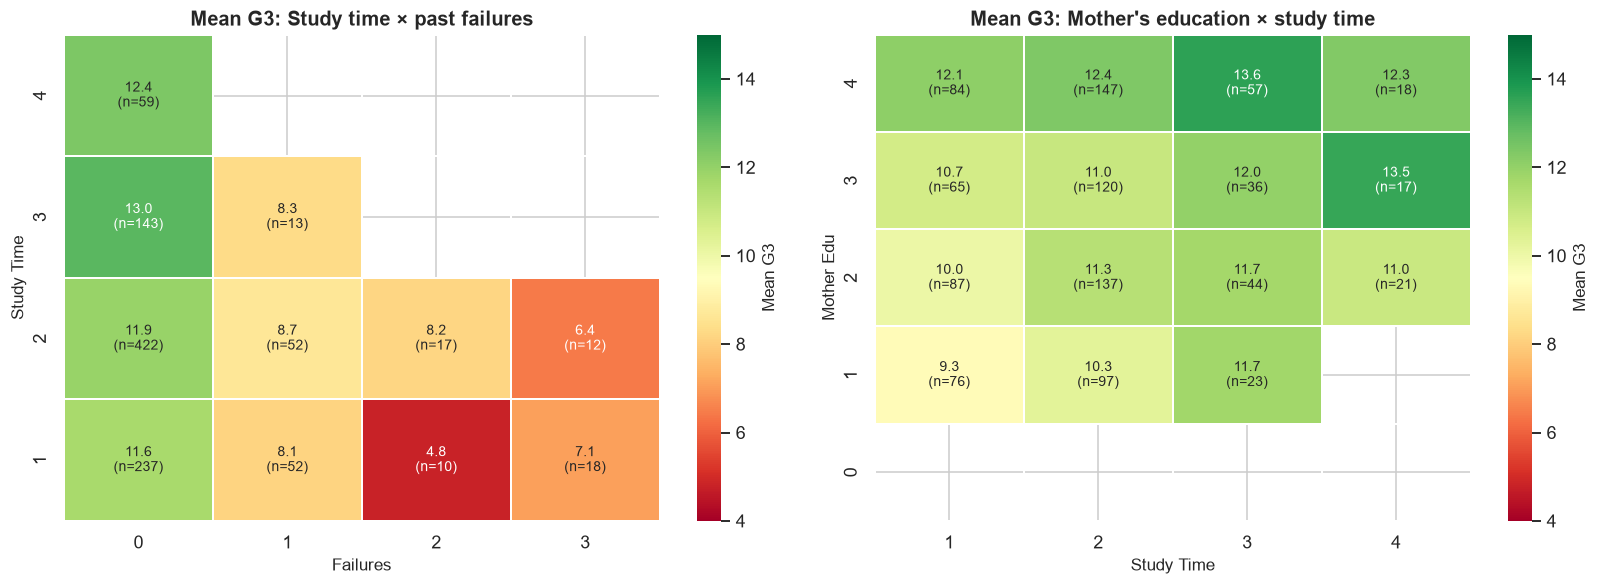

In [39]:
def masked_pivot(index, columns, min_n=10):
    mean = df.pivot_table(index=index, columns=columns, values="G3", aggfunc="mean", observed=True)
    n = df.pivot_table(index=index, columns=columns, values="G3", aggfunc="count", observed=True)
    return mean.where(n >= min_n), n

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (idx, col, title) in zip(axes, [("study_time", "failures", "Study time × past failures"),
                                        ("mother_edu", "study_time", "Mother's education × study time")]):
    pv, n = masked_pivot(idx, col)
    annot = pv.round(1).astype(str) + "\n(n=" + n.reindex_like(pv).fillna(0).astype(int).astype(str) + ")"
    annot = annot.where(pv.notna(), "")
    sns.heatmap(pv, annot=annot, fmt="", cmap="RdYlGn", vmin=4, vmax=15, linewidths=1, linecolor="white",
                cbar_kws={"label": "Mean G3"}, annot_kws={"size": 9}, ax=ax)
    ax.set(title=f"Mean G3: {title}", xlabel=col.replace("_", " ").title(), ylabel=idx.replace("_", " ").title())
    ax.invert_yaxis()
plt.tight_layout()
save_show(fig, "16_two_factor_heatmaps")

pv1, _ = masked_pivot("study_time", "failures")
best_col = int((pv1.idxmax(axis=1) == 0).sum()); n_rows = int(pv1.notna().any(axis=1).sum())
takeaway(f"In <b>{best_col} of {n_rows}</b> study-time levels the 0-failure column has the highest mean grade. "
         f"Mean G3 ranges from <b>{np.nanmin(pv1.values):.1f}</b> to <b>{np.nanmax(pv1.values):.1f}</b> across the combinations shown. "
         f"Compare moving across a row (more failures) with moving down a column (more study time) to see which factor changes the grade more.")

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📊 Visual 17: Pass-rate gaps for risk factors (dumbbell chart)</h3>
For each risk factor, the pass rate of students **with** the factor (red) is compared with students **without** it (green). The longer the line, the bigger the gap. This view is the most useful one for deciding where a school should act.

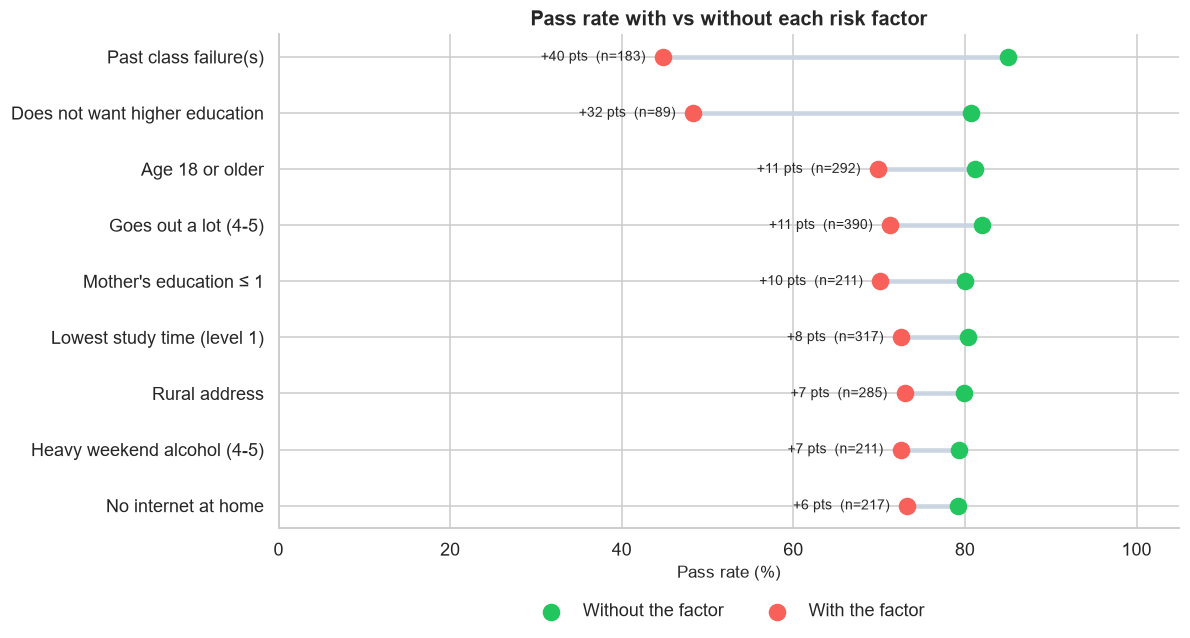

In [40]:
risk_flags = {
    "Past class failure(s)":              df["failures"] > 0,
    "Does not want higher education":     df["wants_higher_edu"] == "No",
    "Lowest study time (level 1)":        df["study_time"] == 1,
    "Heavy weekend alcohol (4-5)":        df["weekend_alcohol"] >= 4,
    "Mother's education ≤ 1":             df["mother_edu"] <= 1,
    "Goes out a lot (4-5)":               df["go_out"] >= 4,
    "Age 18 or older":                    df["age"] >= 18,
    "Rural address":                      df["address"] == "Rural",
    "No internet at home":                df["internet_access"] == "No",
}
rows = []
for name, flag in risk_flags.items():
    rows.append({"factor": name, "with": pass_rate(df.loc[flag, "G3"]), "without": pass_rate(df.loc[~flag, "G3"]),
                 "n_with": int(flag.sum())})
gap = pd.DataFrame(rows).assign(gap=lambda t: t["without"] - t["with"]).sort_values("gap")

fig, ax = plt.subplots(figsize=(11, 6))
ypos = np.arange(len(gap))
ax.hlines(ypos, gap["with"], gap["without"], color="#CBD5E1", lw=3, zorder=1)
ax.scatter(gap["without"], ypos, color=GREEN, s=110, zorder=2, label="Without the factor")
ax.scatter(gap["with"],    ypos, color=RED,   s=110, zorder=2, label="With the factor")
for y, (_, r) in zip(ypos, gap.iterrows()):
    ax.text(min(r["with"], r["without"]) - 2, y, f"{r['gap']:+.0f} pts  (n={r['n_with']})", ha="right", va="center", fontsize=9)
ax.set_yticks(ypos, gap["factor"])
ax.set(title="Pass rate with vs without each risk factor", xlabel="Pass rate (%)", xlim=(0, 105))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
plt.tight_layout()
save_show(fig, "17_risk_factor_dumbbell")

top_g = gap.iloc[-1]; bot_g = gap.iloc[0]
takeaway(f"<b>{top_g['factor']}</b> shows the largest drop in pass rate ({top_g['without']:.0f}% → {top_g['with']:.0f}%, a gap of <b>{top_g['gap']:.0f} points</b>). "
         f"Next largest: " + ", ".join(f"<b>{r['factor']}</b> ({r['gap']:+.0f})" for _, r in gap.iloc[-2:-4:-1].iterrows()) + ". "
         f"The smallest gap is for <b>{bot_g['factor']}</b> ({bot_g['gap']:+.0f} points). Compare group sizes (n) before drawing conclusions.")

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📊 Visual 18: Pair plot of key variables</h3>
A grid of scatter plots and histograms for the main numeric variables, coloured by subject. It is a quick way to check several relationships (and the shape of each variable) at once.

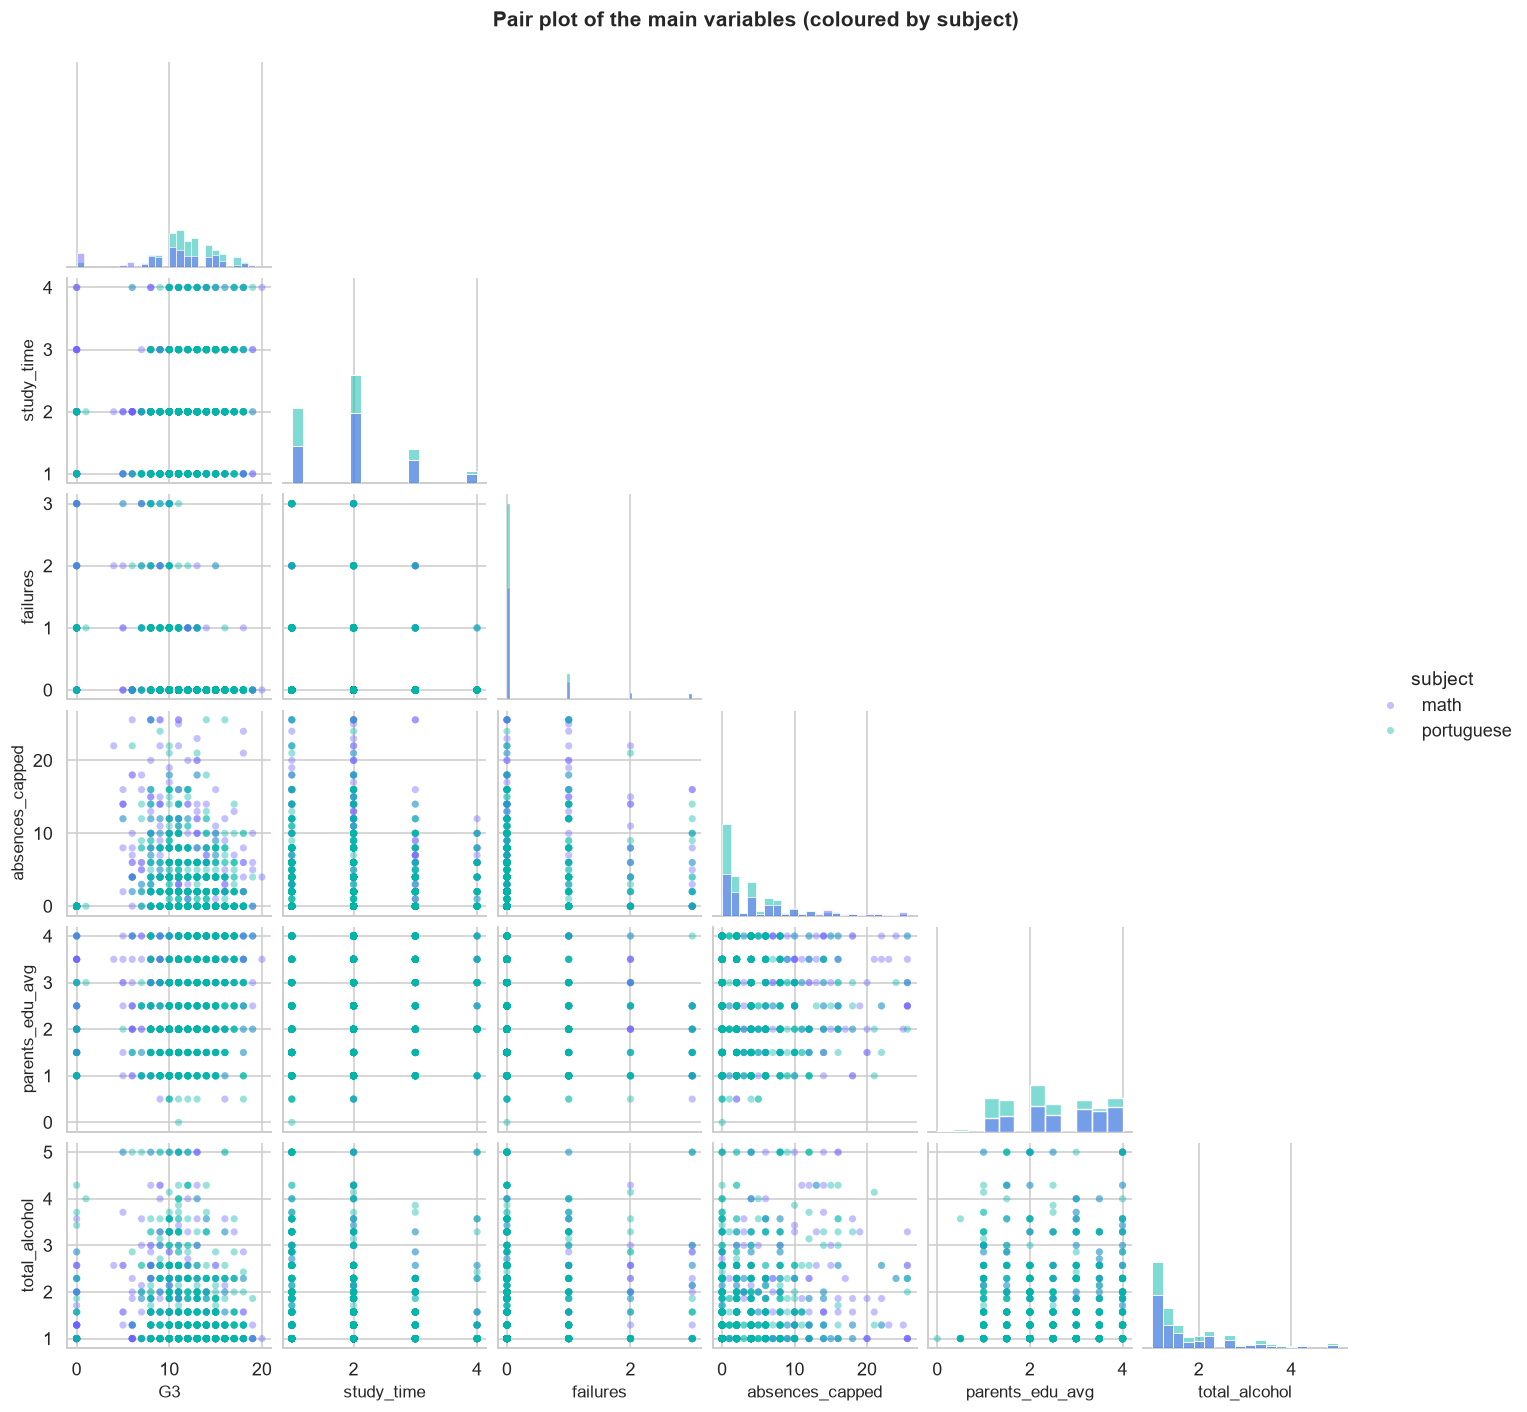

In [41]:
pp_cols = ["G3", "study_time", "failures", "absences_capped", "parents_edu_avg", "total_alcohol"]
g = sns.pairplot(df[pp_cols + ["subject"]], hue="subject", hue_order=SUBJECT, palette=PAL, corner=True,
                 diag_kind="hist", plot_kws={"alpha": .4, "s": 22, "edgecolor": "none"}, height=2.1)
g.figure.suptitle("Pair plot of the main variables (coloured by subject)", fontsize=14, fontweight="bold", y=1.02)
g.figure.savefig("figures/18_pairplot.png", dpi=150, bbox_inches="tight")
plt.show()

sm = df.groupby("subject", observed=True)["G3"].mean()
takeaway("The discrete variables form lines of dots (they are scales, not continuous values). "
         "The two subjects overlap on most panels, so the <b>relationships look similar in both subjects</b>; "
         f"the main difference is the level of G3 (mean {', '.join(f'{s} {v:.1f}' for s, v in sm.items())}).")

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📊 Visual 19: Interactive scatter: every student, with hover details (Plotly)</h3>
An interactive version of the `G1 → G3` relationship. **Hover** over a point to see the student's details; **click a legend entry** to hide/show a subject; **drag** to zoom. Bubble size shows absences.

In [42]:
plot_df = df.assign(absences_size=df["absences_capped"] + 2)             # +2 so students with 0 absences stay visible
fig = px.scatter(plot_df, x="G1", y="G3", color="subject", size="absences_size", size_max=16,
                 color_discrete_map=PAL, opacity=.6,
                 hover_data={"gender": True, "school": True, "failures": True, "study_time": True,
                             "absences": True, "absences_size": False},
                 title="First-period grade (G1) vs final grade (G3): bubble size = absences",
                 labels={"G1": "G1 (first period)", "G3": "G3 (final grade)"})
fig.add_hline(y=PASS_LINE, line_dash="dash", line_color=RED, annotation_text="Pass mark")
fig.update_layout(template="plotly_white", height=520, legend_title_text="Subject")
fig.show()

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

<h3 style="color:#E0443E;border-left:6px solid #E0443E;padding-left:12px;margin-top:22px;">📊 Visual 20: Interactive breakdown: subject → school → performance band (Plotly sunburst)</h3>
Rings show how the students split by **subject → school → performance band**. Slice size = number of students; **colour = mean final grade** (red = low, green = high). Click a slice to zoom in.

In [ ]:
sb = (df.groupby(["subject", "school", "performance_band"], observed=True)["G3"]
        .agg(students="count", mean_G3="mean").reset_index())
sb["performance_band"] = sb["performance_band"].astype(str)
sb["school"] = sb["school"].astype(str)
sb["subject"] = sb["subject"].astype(str)

fig = px.sunburst(sb, path=["subject", "school", "performance_band"], values="students", color="mean_G3",
                  color_continuous_scale="RdYlGn", range_color=(0, 18),
                  title="Students by subject, school and performance band (colour = mean G3)")
fig.update_layout(height=620, template="plotly_white", coloraxis_colorbar_title="Mean G3")
fig.show()

# Parallel categories: how do several factors line up with passing?
fig2 = px.parallel_categories(df.assign(failures=df["failures"].astype(str)),
                              dimensions=["subject", "wants_higher_edu", "failures", "pass_fail"],
                              color="G3", color_continuous_scale="RdYlGn",
                              title="Parallel categories: subject → wants higher education → past failures → pass / fail")
fig2.update_layout(height=480, template="plotly_white")
fig2.show()

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

### ✅ Summary of the multivariate analysis
* The grades `G1`, `G2`, `G3` form one tightly correlated block; no lifestyle variable comes close to them.
* **Failures outweigh study time** when the two are combined; some predictors overlap (e.g. mother's and father's education).
* The risk-factor chart gives a clear order of where pass rates drop most.
* The interactive charts allow the school to explore individual students and groups (subject → school → band).

> **Part 4 complete:** 20 visuals (5 univariate · 8 bivariate · 7 multivariate) with Matplotlib, Seaborn and Plotly.

<a id="5"></a>
<h1 style="background:linear-gradient(90deg,#F8615A,#FFB400);color:white;padding:16px 24px;border-radius:12px;margin:34px 0 12px 0;box-shadow:0 3px 8px rgba(0,0,0,.18);">5️⃣ Insights, Summary & Conclusions</h1>

This final part turns the charts into **actionable insights**. All numbers below are **calculated from the data** (not typed by hand), so they stay correct if the dataset is updated.

| Section | Content |
|---|---|
| 5.1 | Key insights (8) with evidence and a recommended action |
| 5.2 | Recommendations summary |
| 5.3 | Limitations and next steps |
| 5.4 | Conclusion |

<h2 style="color:#E06A00;border-bottom:3px solid #E06A00;padding-bottom:6px;margin-top:30px;">5.1 Key Insights</h2>

In [ ]:
# ---- Compute every number used in the insight cards -----------------------
r1, r2 = df["G1"].corr(df["G3"]), df["G2"].corr(df["G3"])

f0, f1p = df.loc[df["failures"] == 0, "G3"].mean(), df.loc[df["failures"] > 0, "G3"].mean()
pr_f0, pr_f1p = pass_rate(df.loc[df["failures"] == 0, "G3"]), pass_rate(df.loc[df["failures"] > 0, "G3"])
n_f1p = int((df["failures"] > 0).sum())

subj_mean = df.groupby("subject", observed=True)["G3"].mean()
subj_pass = df.groupby("subject", observed=True)["G3"].apply(pass_rate)
subj_chg = df.groupby("subject", observed=True)[["G1", "G3"]].mean().pipe(lambda t: t["G3"] - t["G1"])
hi_s, lo_s = subj_mean.idxmax(), subj_mean.idxmin()

he = df.groupby("wants_higher_edu", observed=True)["G3"].mean()
he_pass = df.groupby("wants_higher_edu", observed=True)["G3"].apply(pass_rate)

st = df.groupby("study_time")["G3"].mean()

n_zero = int(df["zero_grade"].sum())
abs_all, abs_gr = df["absences"].corr(df["G3"]), df_graded["absences"].corr(df_graded["G3"])
zero_abs0 = int((df.loc[df["zero_grade"], "absences"] == 0).sum())

pg = df.pivot_table(index="subject", columns="gender", values="G3", aggfunc="mean", observed=True)
gender_gap = {s: pg.loc[s, "Female"] - pg.loc[s, "Male"] for s in SUBJECT}

r_alc = df["weekday_alcohol"].corr(df["G3"]); r_go = df["go_out"].corr(df["G3"])
r_age = df["age"].corr(df["G3"])
urb = df.groupby("address", observed=True)["G3"].mean()
sup = df.groupby("school_support", observed=True)["G3"].mean()

def card(num, title, finding, evidence, action, color):
    return f"""
    <div style="border:2px solid {color};border-radius:12px;margin:14px 0;overflow:hidden;color:#1a1a1a;background:#fff;">
      <div style="background:{color};color:white;padding:10px 16px;font-size:17px;font-weight:700;">Insight {num} · {title}</div>
      <div style="padding:12px 16px;line-height:1.55;">
        <p style="margin:4px 0;"><b>🔎 Finding:</b> {finding}</p>
        <p style="margin:4px 0;"><b>📈 Evidence:</b> {evidence}</p>
        <p style="margin:4px 0;"><b>🎯 So what / action:</b> {action}</p>
      </div>
    </div>"""

insights = [
 card(1, "Early grades almost decide the final grade",
      f"A student's first- and second-period grades predict the final grade very closely (G1: r = {r1:.2f}, G2: r = {r2:.2f}).",
      "Visual 8 (points hug the diagonal), Visual 14 and 15 (strongest bars).",
      "Use <b>G1 as an early-warning signal</b>: students who start low rarely recover on their own, so support should begin in the first period, not at the end of the year.",
      "#6C63FF"),
 card(2, "Past failures are the strongest warning sign",
      f"Students with at least one past failure average <b>{f1p:.1f}</b> vs <b>{f0:.1f}</b> for those with none, and their pass rate is <b>{pr_f1p:.0f}%</b> vs <b>{pr_f0:.0f}%</b>.",
      f"Visual 6 (boxes fall as failures rise, in both subjects), Visual 16 (failures matter more than study time), Visual 17 (largest pass-rate gaps). Group size: {n_f1p} students.",
      "Create a <b>repeat-failure watch-list</b> with tutoring and regular check-ins; this is a small group with a large payoff.",
      "#E0443E"),
 card(3, f"{lo_s} is clearly harder than {hi_s}",
      f"Mean G3 is <b>{subj_mean[lo_s]:.1f}</b> in {lo_s} vs <b>{subj_mean[hi_s]:.1f}</b> in {hi_s}; pass rate <b>{subj_pass[lo_s]:.0f}%</b> vs <b>{subj_pass[hi_s]:.0f}%</b>. "
      f"Average change from G1 to G3 is {subj_chg[lo_s]:+.2f} in {lo_s} and {subj_chg[hi_s]:+.2f} in {hi_s}.",
      "Visual 1 (density curves), Visual 5 (pass rates) and Visual 13 (progression).",
      f"Put extra resources (remedial classes, smaller groups) into <b>{lo_s}</b>" + (", especially in the second half of the year, when its averages slip." if subj_chg[lo_s] < 0 else "."),
      "#3A86FF"),
 card(4, "Ambition and motivation matter",
      f"Students who want higher education average <b>{he['Yes']:.1f}</b> vs <b>{he['No']:.1f}</b> for those who do not (pass rate {he_pass['Yes']:.0f}% vs {he_pass['No']:.0f}%).",
      "Visual 9 (largest gap among the background factors), Visual 17.",
      "Career guidance and information about university pathways could raise motivation; the group that does not want higher education is small, so it can be targeted directly.",
      "#8338EC"),
 card(5, "Study time helps, but with diminishing returns",
      f"Mean G3 is <b>{st.loc[1]:.1f}</b> at the lowest study level and <b>{st.max():.1f}</b> at the best level (level {st.idxmax()}); "
      f"moving from level 1 to 2 adds <b>{st.loc[2]-st.loc[1]:+.1f}</b>, and from level 2 to the top adds <b>{st.max()-st.loc[2]:+.1f}</b>.",
      "Visual 7 (compare the steps between levels and the overlap of the confidence intervals).",
      "Encourage a <b>minimum study routine</b> (supervised study hall, homework club) rather than only asking for ever longer hours: the largest benefit is in moving students off the lowest level.",
      "#00B8A9"),
 card(6, "Zero grades hide the real effect of absences",
      f"All <b>{zero_abs0}</b> of the <b>{n_zero}</b> students with G3 = 0 have 0 recorded absences. Correlation of absences with G3 is {abs_all:.2f} for everyone but {abs_gr:.2f} once they are excluded.",
      "Visual 11 (zero grades sit only in the 'None' group) and Visual 8 (red crosses).",
      "Review how absences are recorded for students who <b>drop out</b>, and treat G3 = 0 as 'did not complete', not as a normal low grade. Otherwise absence policies will be judged on wrong data.",
      "#F8615A"),
 card(7, "The gender gap depends on the subject",
      " ; ".join(f"In <b>{s}</b> girls differ from boys by <b>{d:+.2f}</b> points" for s, d in gender_gap.items()) + ".",
      "Visual 9 (bars reverse direction between subjects).",
      "Avoid one-size-fits-all gender measures; check subject-specific <b>teaching styles and engagement</b>.",
      "#FFB400"),
 card(8, "Lifestyle and background effects are real but small",
      f"Weekday alcohol (r = {r_alc:.2f}), going out (r = {r_go:.2f}) and age (r = {r_age:.2f}) are only weakly related to G3; "
      f"urban vs rural differ by <b>{urb.get('Urban', np.nan) - urb.get('Rural', np.nan):+.1f}</b> points. "
      f"Extra school support looks 'negative' ({sup['Yes']:.1f} vs {sup['No']:.1f}) because it goes to students who already struggle.",
      "Visual 10, Visual 12, Visual 14 and Visual 15.",
      "Do not target the school's effort at lifestyle alone. Judge support programmes by <b>progress (G3 − G1)</b>, not by raw grades, to avoid reading selection effects as harm.",
      "#16A34A"),
]
display(HTML("".join(insights)))

<h2 style="color:#E06A00;border-bottom:3px solid #E06A00;padding-bottom:6px;margin-top:30px;">5.2 Recommendations Summary</h2>

## Main recommendation

**The school should identify students who are struggling early and give them support before the final examination.** The analysis shows that students' earlier grades and previous class failures are more closely linked to final results than most personal or lifestyle factors.

## Recommended actions

### 1. Support students who score low in the first assessment — High priority
- **Who needs support?** Students who receive low marks in the first assessment (G1).
- **What should the school do?** Check their difficulties, arrange extra help, and speak with them regularly.
- **Why?** G1 and G2 have a strong relationship with the final grade. Waiting until the final exam may be too late.
- **How to check progress:** Compare their next assessment marks with their first assessment marks.

### 2. Give extra attention to students who have failed before — High priority
- **Who needs support?** Students with one or more previous class failures.
- **What should the school do?** Provide individual guidance, subject support, and regular teacher-parent follow-up.
- **Why?** This group has a lower average final grade and pass rate than students with no previous failures.
- **How to check progress:** Review attendance, class participation, homework completion, and assessment marks.

### 3. Strengthen support for Mathematics — Medium priority
- **Who needs support?** Students who are finding Mathematics difficult.
- **What should the school do?** Arrange remedial classes, explain difficult topics in smaller steps, and provide extra practice.
- **Why?** In this dataset, Mathematics has a lower average final grade and pass rate than Portuguese.
- **How to check progress:** Compare Mathematics marks before and after the extra support.

### 4. Encourage students to plan for further education — Medium priority
- **Who needs support?** Students who are unsure about continuing their education.
- **What should the school do?** Provide career guidance, explain further-study options, and invite people to share their education or career experiences.
- **Why?** Students who said they wanted higher education had better average results in this dataset.
- **How to check progress:** Check whether students become more engaged and whether their assessment results improve.

### 5. Help students build a regular study habit — Medium priority
- **Who needs support?** Students who spend very little time studying each week.
- **What should the school do?** Encourage a realistic daily study timetable, supervised study time, and a homework-support group.
- **Why?** The analysis suggests that moving away from the lowest study-time group is associated with better results.
- **How to check progress:** Review study habits and compare assessment marks over time.

### 6. Improve the way zero grades are recorded — Data-quality priority
- **What should the school check?** Students recorded with a final grade of zero.
- **What should the school do?** Confirm whether the student did not complete the course, dropped out, or actually received a zero mark. Record these situations separately.
- **Why?** All 53 students with a final grade of zero had no recorded absences. This suggests that a zero grade may not always mean poor performance or absence.
- **How to check progress:** Keep separate records for completed assessments, non-completion, and dropout.

### 7. Monitor other factors without making assumptions — Ongoing
- **What should the school monitor?** Differences by gender and subject, home background, and lifestyle factors.
- **What should the school do?** Review these patterns regularly, but avoid treating them as the main reason for a student's performance.
- **Why?** Some differences are small or vary by subject. The analysis shows relationships, not proof that one factor causes a result.

## Action plan at a glance

| Priority | Action | Main purpose |
|---|---|---|
| High | Identify low G1 scores and provide early support | Prevent students from falling further behind |
| High | Support students with previous failures | Reduce the risk of repeated failure |
| Medium | Provide extra Mathematics support | Improve understanding and subject results |
| Medium | Offer career and further-education guidance | Encourage motivation and future planning |
| Medium | Build regular study habits | Help students study consistently |
| Data quality | Review and correctly classify zero grades | Make the analysis and school records more accurate |
| Ongoing | Monitor gender and background patterns | Ensure support is fair and appropriate |

## Final recommendation

The school should **focus first on students with low first-assessment marks and students who have failed previously**. These are the clearest warning signs in this dataset. Teachers can identify these students early, understand the reason for their difficulties, and provide tutoring and regular follow-up. The school should then review progress after each assessment and adjust the support when needed.

**Important note:** These findings show relationships in the dataset; they do not prove that any one factor directly causes higher or lower marks. The recommendations should be tested by monitoring students' progress after support is provided.


<h2 style="color:#E06A00;border-bottom:3px solid #E06A00;padding-bottom:6px;margin-top:30px;">5.3 Limitations and Next Steps</h2>
* **Association, not causation.** All findings come from observational data. Support programmes, for example, look "negative" because they are given to weaker students.
* **Rows are enrolments, not unique students.** Without a student ID, students taking both subjects appear twice (noted in Part 0), so the two observations are not fully independent.
* **Small groups.** Some categories (for example high alcohol levels, 3 past failures) have few students, so their averages are less stable; sample sizes are shown in the charts.
* **Self-reported data.** Alcohol use, study time and family relationships come from questionnaires and may be inaccurate.
* **One school year, two schools.** Results may not generalise to other regions or years.

**Possible next steps:** build a predictive model (for example logistic regression or a random forest) to flag students at risk of failing after the first period; test the effect of interventions (before / after G1 → G3 progress); and collect a student ID to separate repeated students.

<h2 style="color:#E06A00;border-bottom:3px solid #E06A00;padding-bottom:6px;margin-top:30px;">5.4 Conclusion</h2>
The analysis combined **cleaning, tabular exploration and 20 visualisations** to answer the question: *what is associated with a student's final grade, and what can a school act on?*

The picture is consistent across tables and charts:

1. **Where the student starts and their history matter most** (earlier grades, past failures).
2. **Motivation and basic study routine** come next (higher-education plans, leaving the lowest study level).
3. **Subject differences are large** (Math is the harder subject) while **lifestyle and background effects are small**.
4. **Data quality matters**: the zero grades hid the real effect of absences until they were examined separately.

Because the strongest signals are visible **after the first grading period**, a school can act early and focus its limited support on the **small group of students with low early grades and repeated failures**.

---
### ✅ Project checklist
| Requirement | Where it is covered |
|---|---|
| Data cleaning and pre-processing | Part 2 |
| Descriptive exploration with tables | Part 3 |
| **EDA with 10+ visuals** (univariate · bivariate · multivariate) | **Part 4: 20 visuals** (Matplotlib, Seaborn, Plotly) |
| **Well-commented notebook, summaries, clean presentation** | Markdown explanations, code comments, 💡 takeaways and ✅ summaries throughout |
| **At least 5 clear insights** | **Part 5.1: 8 insights** with evidence and actions |